# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Ёщик Юлия Андреевна**

**Файлы данных: clients.csv, transactions.csv**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
import re
import pyarrow

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

RAW_CLIENTS = '../data/raw/clients.csv'
RAW_TXN = '../data/raw/transactions.csv'

BASE_START, BASE_END = pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31")
EVAL_START, EVAL_END = pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-30")
BASE_MONTHS, EVAL_MONTHS = 12, 6
DROP_THRESHOLD = 0.5    

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.titlesize": 11, "axes.labelsize": 10})

_log_rows = []

def log_change(field, issue, scope, n_rows, value_before,
               action, value_after, rationale):
    _log_rows.append({
        "field": field,
        "issue": issue,
        "scope": scope,
        "n_rows": int(n_rows),
        "value_before": str(value_before),
        "action": action,
        "value_after": str(value_after),
        "rationale": rationale,
    })

    print(f'[log] {field:20s} | {action:12s} | n={int(n_rows):>6d} | {issue[:70]}')

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
with open(RAW_CLIENTS, encoding='utf-8') as f:
    for _ in range(3):
        print(repr(f.readline()))

'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C005602,1972-05-06,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,09.09.2017,22.04.2018,Не указан,,Нет,,,00468,Да\n'
'C003158,1974-12-06,Ж,Нижний Новгород,Зарплатный,Серебро,Дебетовая,29.10.2016,29.05.2019,Зарплата в другом банке,100200.0,Нет,,,00525,Да\n'


In [3]:
pd.read_csv(RAW_CLIENTS, nrows=5)

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C005602,1972-05-06,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,09.09.2017,22.04.2018,Не указан,NaN,Нет,NaN,NaN,468,Да
1,C003158,1974-12-06,Ж,Нижний Новгород,Зарплатный,Серебро,Дебетовая,29.10.2016,29.05.2019,Зарплата в другом банке,100200.0,Нет,NaN,NaN,525,Да
2,C002080,1984-10-04,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,16.04.2018,20.08.2023,Не указан,30200.0,Да,2024-04,NaN,223,Нет
3,C005617,1968-05-14,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,12.08.2018,28.05.2023,Не указан,55200.0,Нет,NaN,NaN,636,Да
4,C002508,1979-12-17,Ж,Екатеринбург,Массовый,Базовый,Дебетовая,20.02.2022,08.05.2023,Зарплата в нашем банке,68400.0,Да,2024-04,1.0,283,Да


In [4]:
df_clients = pd.read_csv(RAW_CLIENTS)

In [5]:
with open(RAW_TXN, encoding='cp1251') as f:
    for _ in range(3):
        print(repr(f.readline()))

'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990138;C000191;2023-12-19 19:33:11;944,63;RUB;Продукты;5411;Карта;успешно\n'
'990162;C000677;2023-12-28 17:29:02;266,96;RUB;Продукты;5411;Карта;успешно\n'


In [6]:
raw_txn=pd.read_csv(RAW_TXN, nrows=5, encoding='cp1251', sep=';')
raw_txn

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990138,C000191,2023-12-19 19:33:11,"944,63",RUB,Продукты,5411,Карта,успешно
1,990162,C000677,2023-12-28 17:29:02,"266,96",RUB,Продукты,5411,Карта,успешно
2,100001,C005036,2024-01-01 01:28:49,"593,35",RUB,Связь и интернет,4814,СБП,успешно
3,100002,C004346,2024-01-01 02:02:53,"6175,1",RUB,АЗС,5541,Онлайн-банк,успешно
4,100003,C000790,2024-01-01 03:24:16,"1568,65",RUB,Развлечения и досуг,7832,Токен,успешно


In [7]:
df_transactions = pd.read_csv(RAW_TXN, encoding='cp1251', sep=';', decimal=',')

log_change(
    field="amount",
    issue="десятичный разделитель ','",
    scope="все непустые значения transactions.csv",
    n_rows=len(df_transactions[df_transactions['amount'].notna()]),
    value_before=raw_txn.amount[0],
    action="исправлено",
    value_after=df_transactions.amount[0],
    rationale="без приведения суммы не агрегируются",
)

[log] amount               | исправлено   | n=628510 | десятичный разделитель ','


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [8]:
def get_overview(df: pd.DataFrame) -> pd.DataFrame:
    print(f'Форма: {df.shape}')
    
    overview = pd.DataFrame({
        'Тип': df.dtypes.astype(str),
        'Число уникальных': df.nunique(),
        'Число пропущенных': df.isna().sum(),
        '% пропущенных (от строк)': (df.isna().mean() * 100).round(2),
        'Пример': df.iloc[5],
    })
    return overview
    
display(Markdown('**Таблица клиентов**'))
display(get_overview(df_clients))

display(Markdown('**Таблица транзакций**'))
get_overview(df_transactions)

**Таблица клиентов**

Форма: (5696, 16)


,Тип,Число уникальных,Число пропущенных,% пропущенных (от строк),Пример
client_id,str,5641,0,0.00,C001695
birth_date,str,4847,0,0.00,1966-04-28
gender,str,2,0,0.00,Ж
city,str,17,0,0.00,Нижний Новгород
segment,str,4,0,0.00,Массовый
loyalty_tier,str,4,0,0.00,Серебро
card_type,str,3,0,0.00,Дебетовая
registration_date,str,3258,0,0.00,09.04.2014
card_open_date,str,2664,0,0.00,15.01.2018
income_source,str,3,0,0.00,Не указан


**Таблица транзакций**

Форма: (628510, 9)


,Тип,Число уникальных,Число пропущенных,% пропущенных (от строк),Пример
txn_id,int64,627010,0,0.0,100004
client_id,str,5993,0,0.0,C001930
txn_datetime,str,571195,0,0.0,2024-01-01 03:40:18
amount,float64,326447,0,0.0,1615.78
currency,str,3,0,0.0,RUB
category,str,12,0,0.0,Аптеки
mcc_code,int64,9,0,0.0,5912
channel,str,4,0,0.0,СБП
status,str,3,0,0.0,успешно


In [9]:
for col in ["birth_date", "registration_date", "card_open_date", "app_last_login"]:
    pat = df_clients[col].dropna().str.replace(r"\d", "d", regex=True).value_counts()
    print(f"{col}: форматы значений ->", pat.to_dict())
print("txn_datetime: форматы значений ->", df_transactions.txn_datetime.str.replace(r"\d", "d", regex=True).value_counts().to_dict())

birth_date: форматы значений -> {'dddd-dd-dd': 5696}
registration_date: форматы значений -> {'dd.dd.dddd': 5696}
card_open_date: форматы значений -> {'dd.dd.dddd': 5696}
app_last_login: форматы значений -> {'dddd-dd': 3547}
txn_datetime: форматы значений -> {'dddd-dd-dd dd:dd:dd': 578142, 'dddd-dd-dd': 50368}


In [10]:
dt_all = pd.to_datetime(df_transactions.txn_datetime, format="mixed")
blk = df_transactions.txn_id.astype(int) >= 990000
print(f"строк с «выбивающимся» диапазоном txn_id (>=990001): {blk.sum()}; из них вне периода: {int(((dt_all < BASE_START) | (dt_all > EVAL_END + pd.Timedelta(days=1))) [blk].sum())}; "
      f"вне периода среди остальных: {int(((dt_all < BASE_START) | (dt_all >= EVAL_END + pd.Timedelta(days=1)))[~blk].sum())}")

строк с «выбивающимся» диапазоном txn_id (>=990001): 220; из них вне периода: 80; вне периода среди остальных: 0


### 2.2. Дубли

In [11]:
def find_conflicts(df: pd.DataFrame, id_col: str, name: str) -> None:
    display(Markdown(f'**{name}**'))
    full_dup = df.duplicated().sum()
    d = df[df[id_col].isin(df[id_col][df[id_col].duplicated(keep=False)])] \
          .drop_duplicates()
    conflict_ids = d[id_col][d[id_col].duplicated(keep=False)].unique()
    diff_cols = {
        i: [c for c in d.columns if d.loc[d[id_col] == i, c].nunique(dropna=False) > 1]
        for i in conflict_ids
    }

    counts = (pd.Series([x for v in diff_cols.values() for x in v])
                .value_counts().to_dict())

    print(f'Полных дубликатов строк для {name}: {full_dup}')
    print(f"[{name}] id с конфликтами: {len(conflict_ids)} | "
          f"поля, по которым расходятся записи одного {id_col}: {counts}")
    

find_conflicts(df_clients, 'client_id', 'df_clients')
find_conflicts(df_transactions, 'txn_id', 'df_transactions')

**df_clients**

Полных дубликатов строк для df_clients: 40
[df_clients] id с конфликтами: 15 | поля, по которым расходятся записи одного client_id: {'city': 14, 'segment': 12}


**df_transactions**

Полных дубликатов строк для df_transactions: 1274
[df_transactions] id с конфликтами: 226 | поля, по которым расходятся записи одного txn_id: {'txn_datetime': 226}


### 2.3. Соответствие данных описанию полей из задания

In [12]:
CAT_COLS_CLIENTS = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'marketing_opt_in']
CAT_COLS_TXN = ['currency', 'category', 'channel', 'status']

def check_categories(df: pd.DataFrame, COLS: list) -> None:
    for col in COLS:
        print(f'\n{df[col].value_counts(dropna=False)}')

display(Markdown('**Клиенты**'))
display(check_categories(df_clients, CAT_COLS_CLIENTS))

display(Markdown('**Транзакции**'))
check_categories(df_transactions, CAT_COLS_TXN)

**Клиенты**


gender
Ж    2857
М    2839
Name: count, dtype: int64

city
Москва                1091
Новосибирск            735
Санкт-Петербург        646
Нижний Новгород        575
Казань                 538
Екатеринбург           507
г. Новосибирск         197
 москва                190
г. Москва              182
МОСКВА                 179
казань                 158
Н. Новгород            157
Санкт Петербург        122
г. Санкт-Петербург     109
ЕКАТЕРИНБУРГ           107
г.Екатеринбург         104
СПб                     99
Name: count, dtype: int64

segment
Массовый       2930
Зарплатный     1585
Премиальный     933
Private         248
Name: count, dtype: int64

loyalty_tier
Базовый    2824
Серебро    1556
Золото     1041
Платина     275
Name: count, dtype: int64

card_type
Дебетовая      3961
Кредитная      1205
Премиальная     530
Name: count, dtype: int64

income_source
Зарплата в нашем банке     2540
Зарплата в другом банке    1631
Не указан                  1525
Name: count, dtype: int64

h

None

**Транзакции**


currency
RUB    626047
EUR      1252
USD      1211
Name: count, dtype: int64

category
Продукты               165659
Транспорт               65616
Одежда и обувь          64609
АЗС                     58110
Развлечения и досуг     54112
Кафе и рестораны        49179
Аптеки                  46043
Онлайн-сервисы          43543
Связь и интернет        29145
Связь и Интернет        19782
Кафе/рестораны          16526
кафе и рестораны        16186
Name: count, dtype: int64

channel
Карта          317017
СБП            109256
Токен          106787
Онлайн-банк     95450
Name: count, dtype: int64

status
успешно      608489
отклонено     12492
возврат        7529
Name: count, dtype: int64


In [13]:
bd = pd.to_datetime(df_clients.birth_date, format="%Y-%m-%d")
rd = pd.to_datetime(df_clients.registration_date, format="%d.%m.%Y")
cod = pd.to_datetime(df_clients.card_open_date, format="%d.%m.%Y")
age = (EVAL_END - bd).dt.days / 365.25

print(f"возраст на {EVAL_END.date()}: min={age.min():.1f}, max={age.max():.1f}; клиентов младше 18 / старше 100: {(age<18).sum()} / {(age>100).sum()}")
print()
print("карта открыта РАНЬШЕ регистрации:", int((cod < rd).sum()), "| карта открыта позже последней даты периода:", int((cod > EVAL_END).sum()),
      "| регистрация в возрасте <18 лет:", int(((rd - bd).dt.days / 365.25 < 18).sum()))
print()
print("карта открыта: до 2024 / в 2024 / в 2025 ->", int((cod < BASE_START).sum()), int(((cod >= BASE_START) & (cod < EVAL_START)).sum()), int((cod >= EVAL_START).sum()), "(от", len(cod), "строк)")
print()
print("has_mobile_app vs app_last_login:"); print(pd.crosstab(df_clients.has_mobile_app, df_clients.app_last_login.isna(), rownames=["has_mobile_app"], colnames=["app_last_login пуст"]))
print()
print("app_last_login: диапазон", df_clients.app_last_login.min(), "..", df_clients.app_last_login.max())
print()
print("satisfaction_score допустимые значения 1..5:", sorted(df_clients.satisfaction_score.dropna().unique()))
print()
print("branch_code: длины", df_clients.branch_code.astype(str).str.len().value_counts().to_dict(), "| уникальных:", df_clients.branch_code.nunique())

возраст на 2025-06-30: min=22.9, max=88.9; клиентов младше 18 / старше 100: 0 / 0

карта открыта РАНЬШЕ регистрации: 0 | карта открыта позже последней даты периода: 0 | регистрация в возрасте <18 лет: 35

карта открыта: до 2024 / в 2024 / в 2025 -> 4896 462 338 (от 5696 строк)

has_mobile_app vs app_last_login:
app_last_login пуст  False  True 
has_mobile_app                   
Да                    3547      0
Нет                      0   2149

app_last_login: диапазон 2024-01 .. 2025-06

satisfaction_score допустимые значения 1..5: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]

branch_code: длины {3: 5696} | уникальных: 839


### 2.4. Связь между таблицами

In [14]:
txn_clients = set(df_transactions['client_id'].unique())
ref_clients = set(df_clients['client_id'].unique())

print('Клиентов в transactions, которых нет в clients:', len(txn_clients - ref_clients))
print('Клиентов в clients, у которых нет ни одной транзакции:', len(ref_clients - txn_clients))

Клиентов в transactions, которых нет в clients: 359
Клиентов в clients, у которых нет ни одной транзакции: 7


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

**Выводы по аудиту**

1. В таблице clients обнаружено 40 полных дублей строк. При этом на 5696 строк приходится 5641 уникальный client_id, что указывает на наличие записей с одинаковым id, но разными сегментами/городом, при этом определить верную запись невозможно. В transactions выявлено 1274 полных дубля; разница между числом строк (628 510) и уникальных txn_id (627 010) составляет 1500, что также свидетельствует о записях с одинаковым id, но разными атрибутами и завышает активность, если с этим ничего не делать.
2. Поле satisfaction_score пустует в 58.9% случаев, app_last_login - в 37.7%, monthly_income - в 9.1%. Кроме того, в monthly_income присутствует скрытый технический код -999.0.
3. 80 операций датированы вне 2024-01-01..2025-06-30 (в т.ч. будущее до 2026-08) — невозможные даты; в расчет периодов не берем.
4. Поле city содержит 17 уникальных значений вместо фактических 6. В поле category 12 уникальных значений вместо 9. Требуется нормализация справочников.
5. В таблице транзакций присутствуют 359 клиентов, которых нет в справочнике clients. Также 7 клиентов из справочника не совершили ни одной транзакции.
6. В transactions есть отрицательные суммы (минимум -44630.01), которые могут быть возвратами. Даты во всех таблицах загружены как строки, их необходимо перевести в datetime. Начало периода транзакций (декабрь 2023) выходит за рамки базового периода (с 2024-01-01), что нужно учесть при фильтрации.

Данные проблемы не являются блокирующими, но требуют обязательного препроцессинга перед расчетом метрики активности.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [15]:
clients = df_clients.copy()

clients["birth_date"] = pd.to_datetime(clients.birth_date, format="%Y-%m-%d")
clients["registration_date"] = pd.to_datetime(clients.registration_date, format="%d.%m.%Y")
clients["card_open_date"] = pd.to_datetime(clients.card_open_date, format="%d.%m.%Y")
clients["app_last_login"] = pd.to_datetime(clients.app_last_login + "-01", format="%Y-%m-%d")
clients["satisfaction_score"] = pd.to_numeric(clients.satisfaction_score, errors='coerce')

log_change(
    field="registration_date",
    issue="дата хранится строкой в формате DD.MM.YYYY",
    scope="все строки clients.csv",
    n_rows=len(clients),
    value_before=df_clients.registration_date[0],
    action="исправлено",
    value_after=clients.registration_date[0],
    rationale="без datetime64 не считается стаж и не работают сравнения с окнами периода; '%d.%m.%Y' задан явно — иначе авто-парсер для '03.04.2024' берет month-first и молча дает 3 апреля вместо 4 марта",
)

log_change(
    field="card_open_date",
    issue="дата хранится строкой в формате DD.MM.YYYY",
    scope="все строки clients.csv",
    n_rows=len(clients),
    value_before=df_clients.card_open_date[0],
    action="исправлено",
    value_after=clients.card_open_date[0],
    rationale="без datetime64 не считается стаж и не работают сравнения с окнами периода; '%d.%m.%Y' задан явно — иначе авто-парсер для '03.04.2024' берет month-first и молча дает 3 апреля вместо 4 марта",
)

log_change(
    field="app_last_login",
    issue="месяц последнего входа ('YYYY-MM') без дня; при переводе в дату день восстановлен как 01",
    scope="все непустые значения clients.csv",
    n_rows=df_clients["app_last_login"].notna().sum(),
    value_before=df_clients.app_last_login.dropna().iloc[0],
    action="исправлено",
    value_after=clients.app_last_login[0],
    rationale="день из источника не известен; для сравнения с окнами периода достаточно месяца — 1-е число трактуем как начало месяца",
)

log_change(
    field="satisfaction_score",
    issue="порядковая шкала 1..5 хранится как object",
    scope="все непустые значения clients.csv",
    n_rows=df_clients["satisfaction_score"].notna().sum(),
    value_before=df_clients.satisfaction_score.dropna().iloc[0],
    action="исправлено",
    value_after=clients.satisfaction_score[0],
    rationale="числовой тип нужен для описательных статистик; сами значения шкалы не меняются",
)

n_minor_reg = int((((clients.registration_date - clients.birth_date).dt.days / 365.25) < 18).sum())

log_change(
    field="registration_date",
    issue=f"регистрация в возрасте <18 лет: {n_minor_reg} клиентов",
    scope="(registration_date - birth_date).dt.days / 365.25 < 18",
    n_rows=n_minor_reg,
    value_before=f"{n_minor_reg} записей с регистрацией до 18 лет",
    action="оставлено",
    value_after=f"{n_minor_reg} записей без изменений",
    rationale=(
        "детские/юношеские карты — легитимный продукт, открываемый родителем; "
        "даты не противоречат друг другу (карта открыта позже регистрации, и это тоже "
        "проверено — 0 нарушений); registration_date не входит в метрику активности "
        "и в правила групп, поэтому на выводы и на кампанию не влияет"
    ),
)

clients.dtypes
clients.info()

[log] registration_date    | исправлено   | n=  5696 | дата хранится строкой в формате DD.MM.YYYY
[log] card_open_date       | исправлено   | n=  5696 | дата хранится строкой в формате DD.MM.YYYY
[log] app_last_login       | исправлено   | n=  3547 | месяц последнего входа ('YYYY-MM') без дня; при переводе в дату день в
[log] satisfaction_score   | исправлено   | n=  2341 | порядковая шкала 1..5 хранится как object
[log] registration_date    | оставлено    | n=    35 | регистрация в возрасте <18 лет: 35 клиентов
<class 'pandas.DataFrame'>
RangeIndex: 5696 entries, 0 to 5695
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5696 non-null   str           
 1   birth_date          5696 non-null   datetime64[us]
 2   gender              5696 non-null   str           
 3   city                5696 non-null   str           
 4   segment             5696 non-null   str      

In [16]:
transactions = df_transactions.copy()

transactions['txn_datetime'] = pd.to_datetime(transactions.txn_datetime, format="mixed")  

log_change(
    field="txn_datetime",
    issue="в колонке смешаны форматы дат",
    scope="все непустые строки transactions.csv",
    n_rows=int(transactions["txn_datetime"].notna().sum()),
    value_before=df_transactions.txn_datetime[0],
    action="исправлено",
    value_after=transactions.txn_datetime[0],
    rationale="единый тип нужен для помесячной агрегации; "
              "format='mixed' выбран, т.к. источник отдает разные шаблоны",
)

n_txn_0 = len(transactions)
full_dup = df_transactions.duplicated(keep="first").values
transactions = transactions[~full_dup]

log_change(
    field="txn_id",
    issue=f"полные дубли строк (все 9 колонок совпадают): {int(full_dup.sum())} строк",
    scope="txn_raw.duplicated(keep='first') == True",
    n_rows=int(full_dup.sum()),
    value_before=f"{n_txn_0:,} строк",
    action="удалено",
    value_after=f"{len(transactions):,} строк (оставлено первое вхождение)",
    rationale="дубль завышает число операций; копия не несёт новой информации — все поля совпадают",
)

transactions = transactions.sort_values(["txn_id", "txn_datetime"], ascending=[True, False], kind="stable")
extra = transactions.txn_id.duplicated(keep="first")

if extra.any():
    log_change(
        field="txn_id",
        issue=f"тот же txn_id дважды: дата без времени vs со временем; {int(extra.sum())} пар",
        scope="txn_id.duplicated(keep='first') после сортировки (txn_id, has_time desc)",
        n_rows=int(extra.sum()),
        value_before="одна операция записана дважды — без времени и со временем",
        action="удалено",
        value_after="оставлена запись со временем",
        rationale=(
            "это копия одной операции, более полная запись предпочтительнее; "
            "сортировка по (txn_id, has_time) задает порядок явно — результат "
            "воспроизводим, а не зависит от порядка строк в файле"
        ),
    )

transactions = transactions[~extra].sort_index()
assert transactions.txn_id.is_unique, "после разрешения конфликтов txn_id должен быть уникален"

transactions.dtypes

[log] txn_datetime         | исправлено   | n=628510 | в колонке смешаны форматы дат
[log] txn_id               | удалено      | n=  1274 | полные дубли строк (все 9 колонок совпадают): 1274 строк
[log] txn_id               | удалено      | n=   226 | тот же txn_id дважды: дата без времени vs со временем; 226 пар


txn_id                   int64
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency                   str
category                   str
mcc_code                 int64
channel                    str
status                     str
dtype: object

### 3.2. Категориальные признаки

In [17]:
CITY_MAP = {"москва": "Москва", "санктпетербург": "Санкт-Петербург", "спб": "Санкт-Петербург",
            "новосибирск": "Новосибирск", "нижнийновгород": "Нижний Новгород", "нновгород": "Нижний Новгород",
            "екатеринбург": "Екатеринбург", "казань": "Казань"}

def norm_city(x):
    k = re.sub(r"^\s*г\.?\s*", "", x.strip().lower())
    k = re.sub(r"[^а-яё]", "", k)
    return CITY_MAP[k]
    
clients['city'] = clients.city.map(norm_city)

log_change(
    field="city",
    issue="разнобой написания: регистр, префикс 'г.', лишние пробелы и дефисы — ",
    scope="все строки clients.csv",
    n_rows=len(clients),
    value_before='г. Москва ',
    action="нормализация",
    value_after='Москва',
    rationale="сверено со справочником городов; смысл значения не меняется, "
              "нормализация нужна для корректной группировки по городу в разрезах",
)

m_full_dup  = clients.duplicated(keep="first")
n_full_dup  = int(m_full_dup.sum())
n_before_1  = len(clients)

clients = clients.loc[~m_full_dup].reset_index(drop=True)

assert clients["client_id"].is_unique or clients["client_id"].duplicated().any(), \
    "после drop_duplicates полных дублей быть не должно"

log_change(
    field="client_id",
    issue=(
        f"{n_full_dup} строк — точные копии другой строки"
    ),
    scope="clients.csv, все колонки совпадают",
    n_rows=n_full_dup,
    value_before=f"{n_before_1} строк (из них {n_full_dup} — дубли)",
    action="удалено",
    value_after=f"{len(clients)} строк (оставлено первое вхождение)",
    rationale=(
        "точная копия: значения во всех полях совпадают, поэтому выбор "
        "«какое вхождение оставить» не влияет на результат; клиент должен "
        "встречаться в единице наблюдения один раз, иначе он дважды "
        "попадет в знаменатели и в метрику активности"
    ),
)

conf_mask = clients["client_id"].duplicated(keep=False)
conf_ids = clients.loc[conf_mask, "client_id"].unique().tolist()
n_conf_ids = len(conf_ids)
n_conf_rows = int(conf_mask.sum())
n_before_2 = len(clients)

g = clients.loc[conf_mask].groupby("client_id")
disagree_cols = [
    c for c in clients.columns
    if c != "client_id" and (g[c].nunique(dropna=False) > 1).any()
]

clients = (
    clients.sort_values(list(clients.columns), kind="stable")
      .drop_duplicates("client_id", keep="first")
      .reset_index(drop=True)
)
n_after_2 = len(clients)
n_conf_removed = n_before_2 - n_after_2

for c in disagree_cols:
    per_id  = g[c].nunique(dropna=False)
    diff_ids = per_id[per_id > 1].index
    clients.loc[clients["client_id"].isin(diff_ids), c] = np.nan

clients["id_conflict"] = clients["client_id"].isin(conf_ids)

log_change(
    field="client_id",
    issue=(
        f"один client_id с разными записями: {n_conf_ids} id, "
        f"расходятся поля: {', '.join(disagree_cols) or '—'}; "
    ),
    scope="client_id, встречающиеся >1 раза с несовпадающими полями",
    n_rows=n_conf_removed,
    value_before=f"{n_before_2} строк (конфликтных: {n_conf_rows})",
    action="ограничено",
    value_after=(
        f"{n_after_2} строк; поля [{', '.join(disagree_cols)}] → NaN "
        f"у {n_conf_ids} клиентов; флаг id_conflict=True; "
        f"клиенты исключены из правил групп и кампании"
    ),
    rationale=(
        "какая из записей верна, по данным не определить; автоматическое "
        "слияние даст произвольный результат (зависит от порядка строк); "
        "поэтому не выбираем наугад: обнуляем спорные поля у конфликтных id, "
        "ставим флаг id_conflict и исключаем этих клиентов из правил групп — "
        "в кампанию они не попадают"
    ),
)

def to_category_type(df: pd.DataFrame, cols: list) -> None:
    for col in cols:
        df[col] = df[col].astype('category')

to_category_type(clients, CAT_COLS_CLIENTS)
display(clients.dtypes)
clients.city.value_counts()

[log] city                 | нормализация | n=  5696 | разнобой написания: регистр, префикс 'г.', лишние пробелы и дефисы — 
[log] client_id            | удалено      | n=    40 | 40 строк — точные копии другой строки
[log] client_id            | ограничено   | n=    15 | один client_id с разными записями: 15 id, расходятся поля: city, segme


client_id                        str
birth_date            datetime64[us]
gender                      category
city                        category
segment                     category
loyalty_tier                category
card_type                   category
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source               category
monthly_income               float64
has_mobile_app              category
app_last_login        datetime64[us]
satisfaction_score           float64
branch_code                    int64
marketing_opt_in            category
id_conflict                     bool
dtype: object

city
Москва             1619
Санкт-Петербург     965
Новосибирск         924
Нижний Новгород     723
Екатеринбург        711
Казань              685
Name: count, dtype: int64

In [18]:
cat_key = transactions.category.str.lower().str.replace("/", " и ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
canon = transactions.groupby(cat_key).category.agg(lambda s: s.value_counts().index[0])
transactions['category'] = transactions.category.map(lambda x: canon[re.sub(r"\s+", " ", x.lower().replace("/", " и ")).strip()])

log_change(
    field="category",
    issue="разнобой написания: регистр, '/' vs ' и ', лишние пробелы — ",
    scope="все строки transactions.csv",
    n_rows=len(transactions),
    value_before='Связь и Интернет ',
    action="нормализация",
    value_after='Связь и интернет',
    rationale="одна категория записана по-разному (регистр, '/' vs ' и ', пробелы) — для groupby это разные значения; канон взят как самое частое написание",
)

display(transactions['category'].value_counts())
to_category_type(transactions, CAT_COLS_TXN)
transactions.dtypes

[log] category             | нормализация | n=627010 | разнобой написания: регистр, '/' vs ' и ', лишние пробелы — 


category
Продукты               165261
Кафе и рестораны        81701
Транспорт               65453
Одежда и обувь          64435
АЗС                     57976
Развлечения и досуг     53972
Связь и интернет        48829
Аптеки                  45942
Онлайн-сервисы          43441
Name: count, dtype: int64

txn_id                   int64
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency              category
category              category
mcc_code                 int64
channel               category
status                category
dtype: object

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [19]:
display(clients.info())
clients.describe()

<class 'pandas.DataFrame'>
RangeIndex: 5641 entries, 0 to 5640
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5641 non-null   str           
 1   birth_date          5641 non-null   datetime64[us]
 2   gender              5641 non-null   category      
 3   city                5627 non-null   category      
 4   segment             5629 non-null   category      
 5   loyalty_tier        5641 non-null   category      
 6   card_type           5641 non-null   category      
 7   registration_date   5641 non-null   datetime64[us]
 8   card_open_date      5641 non-null   datetime64[us]
 9   income_source       5641 non-null   category      
 10  monthly_income      5127 non-null   float64       
 11  has_mobile_app      5641 non-null   category      
 12  app_last_login      3514 non-null   datetime64[us]
 13  satisfaction_score  2320 non-null   float64       
 14  bra

None

,birth_date,registration_date,card_open_date,monthly_income,app_last_login,satisfaction_score,branch_code
count,5641,5641,5641,5127.000000,3514,2320.000000,5641.000000
mean,1972-01-17 02:35:43.024286,2017-08-19 05:45:38.450629,2020-08-15 02:30:21.379188,94413.378760,2024-09-14 01:14:59.487763,3.341379,515.859068
min,1936-07-24 00:00:00,2010-02-08 00:00:00,2016-01-01 00:00:00,-999.000000,2024-01-01 00:00:00,1.000000,100.000000
25%,1963-06-10 00:00:00,2015-03-06 00:00:00,2018-03-22 00:00:00,51600.000000,2024-05-01 00:00:00,2.000000,305.000000
50%,1973-10-11 00:00:00,2017-07-17 00:00:00,2020-07-10 00:00:00,72100.000000,2024-09-01 00:00:00,3.000000,511.000000
75%,1982-06-11 00:00:00,2020-01-13 00:00:00,2022-11-10 00:00:00,106600.000000,2025-02-01 00:00:00,5.000000,726.000000
max,2002-08-19 00:00:00,2025-03-31 00:00:00,2025-05-16 00:00:00,956000.000000,2025-06-01 00:00:00,5.000000,939.000000
std,NaN,NaN,NaN,83045.543236,NaN,1.392648,243.673124


In [20]:
len(clients[clients.monthly_income < 0]) == len(clients[clients.monthly_income == -999])

True

In [21]:
clients.loc[clients.monthly_income == -999, "monthly_income"] = np.nan

log_change(
    field="monthly_income",
    issue="значение -999 используется как маркер «нет данных»; без обработки попадает в средние и разрезы",
    scope="все строки clients.csv, где monthly_income == -999",
    n_rows=len(df_clients[df_clients.monthly_income == -999]),
    value_before="-999",
    action="исправлено",
    value_after="NaN",
    rationale="отрицательный доход физически невозможен, приведен к NaN, чтобы пропуск обрабатывался единообразно ",
)

[log] monthly_income       | исправлено   | n=    60 | значение -999 используется как маркер «нет данных»; без обработки попа


In [22]:
miss = pd.DataFrame({"n_пропусков": clients[["monthly_income", "app_last_login", "satisfaction_score"]].isna().sum()})
N = len(clients)
miss["знаменатель (кол-во клиентов)"] = N
miss["% пропусков"] = (miss.n_пропусков / N * 100).round(1)
display(miss)

no_app  = clients.has_mobile_app.eq("Нет")
yes_app = clients.has_mobile_app.eq("Да")

print("monthly_income: % пропусков по источнику дохода:       ", (clients.groupby("income_source").monthly_income.apply(lambda s: s.isna().mean()) * 100).round(1).to_dict())
print("monthly_income: % пропусков по сегменту:               ", (clients.groupby("segment").monthly_income.apply(lambda s: s.isna().mean()) * 100).round(1).to_dict())
print("satisfaction_score: % пропусков по сегменту:           ", (clients.groupby("segment").satisfaction_score.apply(lambda s: s.isna().mean()) * 100).round(1).to_dict())
print("satisfaction_score: % пропусков по наличию приложения: ", (clients.groupby("has_mobile_app").satisfaction_score.apply(lambda s: s.isna().mean()) * 100).round(1).to_dict())
print("app_last_login пуст у has_mobile_app=Нет:              ", int((clients.app_last_login.isna() & no_app).sum()), "из", int(no_app.sum()), "| пуст у has_mobile_app=Да:", int((clients.app_last_login.isna() & yes_app).sum()))

,n_пропусков,знаменатель (кол-во клиентов),% пропусков
monthly_income,574,5641,10.2
app_last_login,2127,5641,37.7
satisfaction_score,3321,5641,58.9


monthly_income: % пропусков по источнику дохода:        {'Зарплата в другом банке': 4.5, 'Зарплата в нашем банке': 4.6, 'Не указан': 25.5}
monthly_income: % пропусков по сегменту:                {'Private': 7.9, 'Зарплатный': 6.2, 'Массовый': 12.2, 'Премиальный': 11.4}
satisfaction_score: % пропусков по сегменту:            {'Private': 36.5, 'Зарплатный': 59.4, 'Массовый': 64.5, 'Премиальный': 45.8}
satisfaction_score: % пропусков по наличию приложения:  {'Да': 58.9, 'Нет': 58.8}
app_last_login пуст у has_mobile_app=Нет:               2127 из 2127 | пуст у has_mobile_app=Да: 0


In [23]:
log_change(
    field="monthly_income",
    issue="пусто в источнике; механизм MAR — зависит от income_source и сегмента, MNAR не исключен",
    scope="monthly_income IS NULL",
    n_rows=int(clients["monthly_income"].isna().sum()),
    value_before="NaN",
    action="оставлено",
    value_after="NaN",
    rationale="заполнение средним сжало бы разброс; статистики считаем по наблюдаемым значениям с явным n",
)

log_change(
    field="satisfaction_score",
    issue="не ответил на опрос; механизм MAR — доля ответивших зависит от сегмента",
    scope="satisfaction_score IS NULL",
    n_rows=int(clients["satisfaction_score"].isna().sum()),
    value_before="NaN",
    action="оставлено",
    value_after="NaN",
    rationale="оценка порядковая 1..5, заполнять нечем; сводки только по ответившим с явным n",
)

log_change(
    field="app_last_login",
    issue="структурный пропуск: у клиентов без приложения входа быть не может",
    scope="has_mobile_app = 'Нет' AND app_last_login IS NULL",
    n_rows=int((clients["has_mobile_app"].eq("Нет") & clients["app_last_login"].isna()).sum()),
    value_before="NaN",
    action="оставлено",
    value_after="NaN",
    rationale="пропуск «неприменимо»: логин в приложении невозможен",
)

[log] monthly_income       | оставлено    | n=   574 | пусто в источнике; механизм MAR — зависит от income_source и сегмента,
[log] satisfaction_score   | оставлено    | n=  3321 | не ответил на опрос; механизм MAR — доля ответивших зависит от сегмент
[log] app_last_login       | оставлено    | n=  2127 | структурный пропуск: у клиентов без приложения входа быть не может


In [24]:
display(transactions.info())
transactions.describe()

<class 'pandas.DataFrame'>
Index: 627010 entries, 0 to 628509
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        627010 non-null  int64         
 1   client_id     627010 non-null  str           
 2   txn_datetime  627010 non-null  datetime64[us]
 3   amount        627010 non-null  float64       
 4   currency      627010 non-null  category      
 5   category      627010 non-null  category      
 6   mcc_code      627010 non-null  int64         
 7   channel       627010 non-null  category      
 8   status        627010 non-null  category      
dtypes: category(4), datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 35.4 MB


None

,txn_id,txn_datetime,amount,mcc_code
count,627010.000000,627010,627010.000000,627010.000000
mean,414613.365890,2024-09-24 15:00:31.348729,1870.358875,5591.062487
min,100001.000000,2023-12-19 19:33:11,-44630.010000,4111.000000
25%,256753.250000,2024-05-18 19:34:50.750000,472.850000,5411.000000
50%,413505.500000,2024-09-21 13:58:08.500000,1074.730000,5541.000000
75%,570257.750000,2025-01-25 15:11:08.750000,2262.730000,5812.000000
max,990220.000000,2026-08-03 12:58:04,208046.430000,7832.000000
std,182638.911686,NaN,2705.382444,857.276114


### В транзакциях пропусков нет ни в каком поле

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [25]:
def tukey(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
    
def z3(s):
    z = (s - s.mean()) / s.std(); return z.abs() > 3
    
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return (0.6745 * (s - med) / mad).abs() > 3.5

inc = clients.monthly_income.dropna()
lo, hi = tukey(inc)

det = pd.DataFrame({"правило": ["Тьюки (Q1-1,5 МКР, Q3+1,5 МКР)", "три сигмы", "робастная z (МАО), |z|>3,5", "бизнес: доход < 1000 руб/мес", "бизнес: доход > 1 млн руб/мес"],
                    "границы": [f"{lo:,.0f} .. {hi:,.0f}", f"{inc.mean()-3*inc.std():,.0f} .. {inc.mean()+3*inc.std():,.0f}", "по МАО", "< 1 000", "> 1 000 000"],
                    "n помечено": [int(((inc < lo) | (inc > hi)).sum()), int(z3(inc).sum()), int(robust_z(inc).sum()), int((inc < 1000).sum()), int((inc > 1_000_000).sum())]})

det["% от наблюдаемых доходов"] = (det["n помечено"] / len(inc) * 100).round(2)

print(f"monthly_income: n наблюдаемых = {len(inc)}"); display(det)

by_seg = clients.groupby("segment").monthly_income.apply(lambda s: int(((s > hi)).sum()))

print("выше верхней границы Тьюки по сегментам (контекстный выброс):", by_seg.to_dict(), "| медиана дохода по сегментам:", clients.groupby("segment").monthly_income.median().round(0).to_dict())

low = inc[inc < 1000]
print("значения < 1000: min/median/max =", low.min(), low.median(), low.max(), "| у них сегменты:", clients.loc[low.index, "segment"].value_counts().to_dict())
print("если умножить на 1000: медиана =", round(low.median() * 1000), "руб/мес — сопоставимо с медианой остальных:", round(inc[inc >= 1000].median()))

monthly_income: n наблюдаемых = 5067


,правило,границы,n помечено,% от наблюдаемых доходов
0,"Тьюки (Q1-1,5 МКР, Q3+1,5 МКР)","-29,825 .. 189,575",428,8.45
1,три сигмы,"-153,098 .. 344,184",120,2.37
2,"робастная z (МАО), |z|>3,5",по МАО,392,7.74
3,бизнес: доход < 1000 руб/мес,< 1 000,162,3.20
4,бизнес: доход > 1 млн руб/мес,> 1 000 000,0,0.00


выше верхней границы Тьюки по сегментам (контекстный выброс): {'Private': 203, 'Зарплатный': 14, 'Массовый': 4, 'Премиальный': 207} | медиана дохода по сегментам: {'Private': 340400.0, 'Зарплатный': 75800.0, 'Массовый': 59700.0, 'Премиальный': 145650.0}
значения < 1000: min/median/max = 19.3 76.9 926.2 | у них сегменты: {'Массовый': 70, 'Зарплатный': 51, 'Премиальный': 33, 'Private': 8}
если умножить на 1000: медиана = 76900 руб/мес — сопоставимо с медианой остальных: 73800


In [26]:
low_idx = clients.index[clients.monthly_income < 1000]
clients["income_rescaled"] = False
clients.loc[low_idx, "income_rescaled"] = True
low_idx = clients.index[clients["monthly_income"] < 1000]
before = clients.loc[low_idx, "monthly_income"].copy()
q1_inc, q3_inc = clients["monthly_income"].quantile([0.25, 0.75])
iqr_inc = q3_inc - q1_inc
hi_inc = q3_inc + 1.5 * iqr_inc

log_change(
    field="monthly_income",
    issue=(
        "доход < 1000 руб/мес,вероятно, записаны в тысячах рублей (разные единицы в источниках)"
    ),
    scope="monthly_income < 1000",
    n_rows=int((clients.monthly_income<1000).sum()),
    value_before="19.3",
    action="исправлено",
    value_after="19300",
    rationale=(
        "после ×1000 медиана пересчитанной группы совпадает с медианой "
        "остальных клиентов — единицы согласуются; источником не подтверждено, "
        "поэтому оставлен флаг income_rescaled для проверки чувствительности; "
        "доход не входит в правила групп, на выводы влияет только через "
        "описательные статистики — там n указывается отдельно"
    ),
)

clients.loc[low_idx, "monthly_income"] = before * 1000

log_change(
    field="monthly_income",
    issue=(
        f"доходы выше границы Тьюки Q3+1.5·IQR = {hi_inc:,.0f}"
    ),
    scope=f"monthly_income > Q3 + 1.5·IQR = {hi_inc:.0f}",
    n_rows=int((clients["monthly_income"] > hi_inc).sum()),
    value_before="956000",
    action="оставлено",
    value_after="956000",
    rationale=(
        "для Private и Премиального такие доходы правдоподобны"
    ),
)

rows = []
ok_rub = transactions[(transactions.status == "успешно") & (transactions.currency == "RUB") & (transactions.txn_datetime >= BASE_START) & (transactions.txn_datetime < EVAL_END + pd.Timedelta(days=1))]
for cat, s in ok_rub.groupby("category", observed=True).amount:
    lo_, hi_ = tukey(s); rows.append((cat, len(s), round(s.median(), 0), round(hi_, 0), int((s > hi_).sum()), round((s > hi_).mean() * 100, 1), round(s.max(), 0)))
amt_out = pd.DataFrame(rows, columns=["категория", "n операций", "медиана, руб", "верхняя граница Тьюки, руб", "n выше границы", "% от операций категории", "максимум, руб"])
display(amt_out)
flag_amt = pd.Series(False, index=ok_rub.index)
for cat, s in ok_rub.groupby("category", observed=True).amount:
    flag_amt[s.index] = s > tukey(s)[1]
print(f"всего помечено: {flag_amt.sum():,} из {len(ok_rub):,} успешных RUB-операций ({flag_amt.mean()*100:.1f}%); три сигмы по всей выборке: {int(z3(ok_rub.amount).sum()):,}")
print("чувствительность среднего чека: со всеми операциями =", round(ok_rub.amount.mean(), 1), "руб; без помеченных =", round(ok_rub.amount[~flag_amt].mean(), 1), "руб; медиана =", round(ok_rub.amount.median(), 1), "(медиана не меняется)")

[log] monthly_income       | исправлено   | n=   162 | доход < 1000 руб/мес,вероятно, записаны в тысячах рублей (разные едини
[log] monthly_income       | оставлено    | n=   445 | доходы выше границы Тьюки Q3+1.5·IQR = 189,575


,категория,n операций,"медиана, руб","верхняя граница Тьюки, руб",n выше границы,% от операций категории,"максимум, руб"
0,АЗС,55743,1855.0,6037.0,3295,5.9,43227.0
1,Аптеки,44411,799.0,2594.0,2589,5.8,14080.0
2,Кафе и рестораны,78723,1551.0,5058.0,4713,6.0,46762.0
3,Одежда и обувь,61191,4158.0,13569.0,3592,5.9,77686.0
4,Онлайн-сервисы,42116,507.0,1650.0,2492,5.9,8771.0
5,Продукты,159861,982.0,3190.0,9246,5.8,32091.0
6,Развлечения и досуг,51663,2592.0,8499.0,3050,5.9,67702.0
7,Связь и интернет,47333,599.0,1946.0,2730,5.8,10000.0
8,Транспорт,63549,99.0,324.0,3609,5.7,2074.0


всего помечено: 35,316 из 604,590 успешных RUB-операций (5.8%); три сигмы по всей выборке: 11,973
чувствительность среднего чека: со всеми операциями = 1894.4 руб; без помеченных = 1591.4 руб; медиана = 1089.7 (медиана не меняется)


In [27]:
log_change(
    field="amount",
    issue="суммы выше границы Тьюки",
    scope="успешные RUB-операции с amount > верхней границы Тьюки своей категории",
    n_rows=int(flag_amt.sum()),
    value_before="208046.43",
    action="оставлено",
    value_after="208046.43",
    rationale="положительная асимметрия — норма для чеков; "
)

log_change(
    field="amount",
    issue="отрицательные суммы — это возвраты, а не ошибки знака",
    scope="status = 'возврат'",
    n_rows=int((transactions["status"] == "возврат").sum()),
    value_before="-44630.01",
    action="оставлено",
    value_after="-44630.01",
    rationale=(
        "возврат — не покупка клиента; это бизнес-операция, а не выброс "
        "(проверено по источнику: все суммы с этим статусом отрицательные); "
        "в метрике активности возвраты не участвуют"
    ),
)

log_change(
    field="txn_id",
    issue="блок из 220 строк с txn_id 990001..990220 вне общей нумерации; 80 из них датированы вне периода",
    scope="txn_id >= 990000",
    n_rows=int((transactions["txn_id"].astype(int) >= 990000).sum()),
    value_before="990001",
    action="оставлено",
    value_after="990001",
    rationale=(
        "содержимое неотличимо от остальных операций (суммы, каналы, статусы); "
        "причина разрыва нумерации установить нельзя; удалять целиком без "
        "доказательства ошибки нельзя"
    ),
)

age_s = (EVAL_END - clients["birth_date"]).dt.days / 365.25
age_lo, age_hi = tukey(age_s)
n_age_out = int(((age_s < age_lo) | (age_s > age_hi)).sum())
print(
    f"возраст: границы Тьюки {age_lo:.1f}..{age_hi:.1f} лет | "
    f"помечено {n_age_out} -> выбросов нет, решений не требуется"
)

[log] amount               | оставлено    | n= 35316 | суммы выше границы Тьюки
[log] amount               | оставлено    | n=  7516 | отрицательные суммы — это возвраты, а не ошибки знака
[log] txn_id               | оставлено    | n=   220 | блок из 220 строк с txn_id 990001..990220 вне общей нумерации; 80 из н
возраст: границы Тьюки 14.5..90.6 лет | помечено 0 -> выбросов нет, решений не требуется


In [28]:
transactions.describe()

,txn_id,txn_datetime,amount,mcc_code
count,627010.000000,627010,627010.000000,627010.000000
mean,414613.365890,2024-09-24 15:00:31.348729,1870.358875,5591.062487
min,100001.000000,2023-12-19 19:33:11,-44630.010000,4111.000000
25%,256753.250000,2024-05-18 19:34:50.750000,472.850000,5411.000000
50%,413505.500000,2024-09-21 13:58:08.500000,1074.730000,5541.000000
75%,570257.750000,2025-01-25 15:11:08.750000,2262.730000,5812.000000
max,990220.000000,2026-08-03 12:58:04,208046.430000,7832.000000
std,182638.911686,NaN,2705.382444,857.276114


In [29]:
q1_inc, q3_inc = transactions["amount"].quantile([0.90, 0.99])
print(q1_inc, q3_inc, max(transactions.amount))

4386.253999999999 12761.619500000048 208046.43


In [30]:
transactions.nlargest(10, 'amount')

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
91921,191686,C003418,2024-03-25 00:00:00,208046.43,RUB,Одежда и обувь,5651,Карта,отклонено
446707,545532,C002076,2024-12-28 15:36:59,93533.89,RUB,Одежда и обувь,5651,Карта,отклонено
160492,260081,C005215,2024-05-21 10:11:36,83453.91,RUB,Одежда и обувь,5651,СБП,отклонено
296691,395900,C002029,2024-09-07 12:01:35,77686.23,RUB,Одежда и обувь,5651,СБП,успешно
8765,108725,C002697,2024-01-10 18:42:49,73857.22,RUB,Одежда и обувь,5651,Токен,отклонено
358701,457750,C005100,2024-10-25 23:45:10,73222.81,RUB,Одежда и обувь,5651,Карта,успешно
296811,396019,C003144,2024-09-07 13:10:09,72058.06,RUB,Одежда и обувь,5651,Онлайн-банк,отклонено
545314,649069,C000420,2025-04-09 21:56:42,72043.07,RUB,Одежда и обувь,5651,Карта,успешно
444882,543714,C002975,2024-12-27 13:02:48,71978.40,RUB,Одежда и обувь,5651,Карта,отклонено
166686,266260,C004313,2024-05-26 14:55:18,71711.75,RUB,Одежда и обувь,5651,Карта,отклонено


### Суммы операций имеют правостороннюю асимметрию, типичную для денежных величин

### 3.5. Фильтры, применяемые перед расчетом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [31]:
clients["in_cohort"] = (~clients.id_conflict) & (clients.card_open_date < BASE_START)
in_dir = transactions.client_id.isin(clients.client_id)
in_per = (transactions.txn_datetime >= BASE_START) & (transactions.txn_datetime < EVAL_END + pd.Timedelta(days=1))
is_ok = transactions.status == "успешно"
coh_ids = set(clients.client_id[clients.in_cohort])
steps = [("сырой файл transactions.csv", len(df_transactions), df_transactions.client_id.nunique(), None),
         ("после удаления дублей txn_id", len(transactions), transactions.client_id.nunique(), None),
         ("+ дата в периоде 2024-01-01..2025-06-30", int(in_per.sum()), transactions.client_id[in_per].nunique(), None),
         ("+ статус «успешно» (без отклонено, возврат)", int((in_per & is_ok).sum()), transactions.client_id[in_per & is_ok].nunique(), None),
         ("+ клиент есть в справочнике действующих", int((in_per & is_ok & in_dir).sum()), transactions.client_id[in_per & is_ok & in_dir].nunique(), None),
         ("+ клиент оцениваем (карта до 2024, нет конфликта id)", int((in_per & is_ok & transactions.client_id.isin(coh_ids)).sum()), transactions.client_id[in_per & is_ok & transactions.client_id.isin(coh_ids)].nunique(), None)]
funnel = pd.DataFrame(steps, columns=["шаг", "строк операций", "клиентов", "x"]).drop(columns="x")
funnel["убрано строк на шаге"] = (funnel["строк операций"].shift(1) - funnel["строк операций"]).fillna(0).astype(int)
display(funnel)
cf = pd.DataFrame([("справочник, сырой", len(df_clients)), ("после удаления дублей client_id", len(clients)), ("- конфликт id (спорные атрибуты)", int(clients.id_conflict.sum())),
                   ("- карта открыта в 2024 (неполная база)", int(((clients.card_open_date >= BASE_START) & (clients.card_open_date < EVAL_START) & ~clients.id_conflict).sum())),
                   ("- карта открыта в 2025 (базы нет)", int(((clients.card_open_date >= EVAL_START) & ~clients.id_conflict).sum())),
                   ("= оцениваемые клиенты (cohort)", int(clients.in_cohort.sum()))], columns=["шаг", "клиентов"])
display(cf)
print("EUR/USD среди успешных операций периода:", int(((transactions.currency != "RUB") & in_per & is_ok).sum()), "строк — остаются в счетчике, исключаются из сумм")

,шаг,строк операций,клиентов,убрано строк на шаге
0,сырой файл transactions.csv,628510,5993,0
1,после удаления дублей txn_id,627010,5993,1500
2,+ дата в периоде 2024-01-01..2025-06-30,626930,5993,80
3,"+ статус «успешно» (без отклонено, возврат)",606960,5992,19970
4,+ клиент есть в справочнике действующих,576988,5633,29972
5,"+ клиент оцениваем (карта до 2024, нет конфлик...",564823,4841,12165


,шаг,клиентов
0,"справочник, сырой",5696
1,после удаления дублей client_id,5641
2,- конфликт id (спорные атрибуты),15
3,- карта открыта в 2024 (неполная база),456
4,- карта открыта в 2025 (базы нет),329
5,= оцениваемые клиенты (cohort),4841


EUR/USD среди успешных операций периода: 2370 строк — остаются в счетчике, исключаются из сумм


In [32]:
log_change(
    field="txn_datetime",
    issue="операции вне периода 2024-01-01..2025-06-30",
    scope="dt < 2024-01-01 OR dt >= 2025-07-01",
    n_rows=int(((transactions["txn_datetime"] < BASE_START) |
                (transactions["txn_datetime"] >= EVAL_END + pd.Timedelta(days=1))).sum()),
    value_before=f"{transactions['txn_datetime'].min():%Y-%m-%d}",
    action="удалено",
    value_after="в clean 0 строк вне периода",
    rationale=(
        "даты после 2025-06-30 физически невозможны: справочник — срез "
        "на эту дату; исправить год по данным нельзя; на выводы не влияют"
    ),
)

log_change(
    field="status",
    issue=(
        f"не дают активности: «отклонено» — "
        f"{int((transactions['status'] == 'отклонено').sum()):,} строк, "
        f"«возврат» — {int((transactions['status'] == 'возврат').sum()):,} строк; "
        f"всего {(transactions['status'] != 'успешно').sum():,} из {len(transactions):,} "
        f"({(transactions['status'] != 'успешно').mean():.1%})"
    ),
    scope="status != 'успешно'",
    n_rows=int((transactions["status"] != "успешно").sum()),
    value_before="успешно / отклонено / возврат",
    action="ограничено",
    value_after=(
        f"строки остаются в clean; в метрику активности идут только "
        f"«успешно» ({int((transactions['status'] == 'успешно').sum()):,} операций)"
    ),
    rationale=(
        "отклонённая операция не состоялась, возврат — не покупка клиента; "
        "если считать их активностью, клиент выглядит активнее, чем есть; "
        "поэтому метрика = число успешных операций, остальные статусы "
        "сохранены для анализа отказов и возвратов"
    ),
)

log_change(
    field="currency",
    issue=(
        f"валютные операции: {int((transactions['currency'] != 'RUB').sum()):,} строк "
        f"({(transactions['currency'] != 'RUB').mean():.1%}) — "
        f"{', '.join(f'{k}: {v}' for k, v in transactions.loc[transactions['currency'] != 'RUB', 'currency'].value_counts().items())}; "
        f"курса в данных нет"
    ),
    scope="currency != 'RUB'",
    n_rows=int((transactions["currency"] != "RUB").sum()),
    value_before="RUB, EUR, USD",
    action="ограничено",
    value_after="строки остаются в счетчике операций; из суммовых расчетов исключены",
    rationale=(
        "для метрики «число операций» валюта не важна — клиент совершил "
        "операцию независимо от валюты; суммировать рубли с EUR/USD нельзя, "
        "курса в данных нет"
    ),
)

log_change(
    field="client_id (transactions)",
    issue=(
        f"операции {transactions.loc[~in_dir, 'client_id'].nunique()} client_id, "
        f"отсутствующих в справочнике действующих клиентов "
        f"({int((~in_dir).sum()):,} строк): ушли до 30.06.2025 "
        f"или не попали в срез"
    ),
    scope="client_id из transactions, отсутствующие в clients",
    n_rows=int((~in_dir).sum()),
    value_before=f"{transactions.loc[~in_dir, 'client_id'].nunique()} id, {int((~in_dir).sum()):,} строк",
    action="ограничено",
    value_after=(
        "строки оставлены для анализа оттока; добавлен флаг in_directory=False; "
        "из правил групп и метрики клиента исключены"
    ),
    rationale=(
        "у них нет атрибутов и marketing_opt_in — кампания их не достигнет; "
        "но они часть реального снижения активности: клиенты, ушедшие до среза, "
        "не должны молча выпадать из данных, иначе оценка падения сместится "
        "вверх (останутся только те, кто остался)"
    ),
)

log_change(
    field="card_open_date",
    issue=(
        f"карта открыта начиная с {BASE_START:%Y-%m-%d}: "
        f"{int((clients['card_open_date'] >= BASE_START).sum())} клиентов — "
        f"базовый период неполный или отсутствует (операции начинаются "
        f"с даты открытия карты)"
    ),
    scope=f"card_open_date >= {BASE_START:%Y-%m-%d}",
    n_rows=int((clients["card_open_date"] >= BASE_START).sum()),
    value_before=(
        f"{clients.loc[clients['card_open_date'] >= BASE_START, 'card_open_date'].min():%Y-%m-%d} .. "
        f"{clients.loc[clients['card_open_date'] >= BASE_START, 'card_open_date'].max():%Y-%m-%d}"
    ),
    action="ограничено",
    value_after="добавлен флаг in_cohort=False; из оценки падения исключены",
    rationale=(
        "месячные средние нельзя сравнить: у них нет 12 месяцев базы, "
        "а первые месяцы после открытия карты — естественный разгон, "
        "не связанный с изменением поведения; без исключения их «рост с нуля» "
        "в базовом периоде выглядел бы как падение относительно 2024"
    ),
)

log_change(
    field="client_id (без операций)",
    issue=(
        f"{int((~clients['client_id'].isin(transactions['client_id'].unique())).sum())} "
        f"клиентов есть в справочнике, но нет ни одной операции "
        f"в transactions (карты открыты в 2025)"
    ),
    scope="client_id из clients, отсутствующие в transactions",
    n_rows=int((~clients["client_id"].isin(transactions["client_id"].unique())).sum()),
    value_before="—",
    action="удалено",
    value_after="из clean исключены вместе с клиентами новых карт",
    rationale=(
        "без операций в базовом периоде падение оценить нельзя — "
        "нет знаменателя; это те же клиенты новых карт, что и в логе "
        "card_open_date, поэтому они уже помечены in_cohort=False "
        "и в оценку падения не входят"
    ),
)

[log] txn_datetime         | удалено      | n=    80 | операции вне периода 2024-01-01..2025-06-30
[log] status               | ограничено   | n= 19975 | не дают активности: «отклонено» — 12,459 строк, «возврат» — 7,516 стро
[log] currency             | ограничено   | n=  2456 | валютные операции: 2,456 строк (0.4%) — EUR: 1247, USD: 1209, RUB: 0; 
[log] client_id (transactions) | ограничено   | n= 30959 | операции 359 client_id, отсутствующих в справочнике действующих клиент
[log] card_open_date       | ограничено   | n=   788 | карта открыта начиная с 2024-01-01: 788 клиентов — базовый период непо
[log] client_id (без операций) | удалено      | n=     7 | 7 клиентов есть в справочнике, но нет ни одной операции в transactions


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [33]:
cleaning_log = pd.DataFrame(_log_rows, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

cleaning_log.head()

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,amount,"десятичный разделитель ','",все непустые значения transactions.csv,628510,"944,63",исправлено,944.63,без приведения суммы не агрегируются
1,registration_date,дата хранится строкой в формате DD.MM.YYYY,все строки clients.csv,5696,09.09.2017,исправлено,2017-09-09 00:00:00,без datetime64 не считается стаж и не работают...
2,card_open_date,дата хранится строкой в формате DD.MM.YYYY,все строки clients.csv,5696,22.04.2018,исправлено,2018-04-22 00:00:00,без datetime64 не считается стаж и не работают...
3,app_last_login,месяц последнего входа ('YYYY-MM') без дня; пр...,все непустые значения clients.csv,3547,2024-04,исправлено,NaT,день из источника не известен; для сравнения с...
4,satisfaction_score,порядковая шкала 1..5 хранится как object,все непустые значения clients.csv,2341,1.0,исправлено,nan,числовой тип нужен для описательных статистик;...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

OK: операций 576988 | клиентов 5633


,признак,ед,n,среднее,медиана,s,МКР,МАО,асимметрия,выбор
0,monthly_income,руб/мес,5067,99118.2,73900.0,83297.3,55950.0,24200.0,3.60,медиана и МКР (скошено вправо)
1,возраст на 30.06.2025,лет,5641,53.5,51.7,14.0,19.0,9.4,0.56,медиана и МКР (скошено вправо)
2,сумма успешной RUB-операции,руб,604590,1894.4,1089.7,2589.7,1774.0,734.6,4.76,медиана и МКР (скошено вправо)


satisfaction_score — порядковая шкала 1-5 (n ответивших = 2320 из 5641 клиентов)
доли оценок среди ответивших (знаменатель 2320 ): {1: 12.9, 2: 18.5, 3: 18.6, 4: 21.5, 5: 28.5}


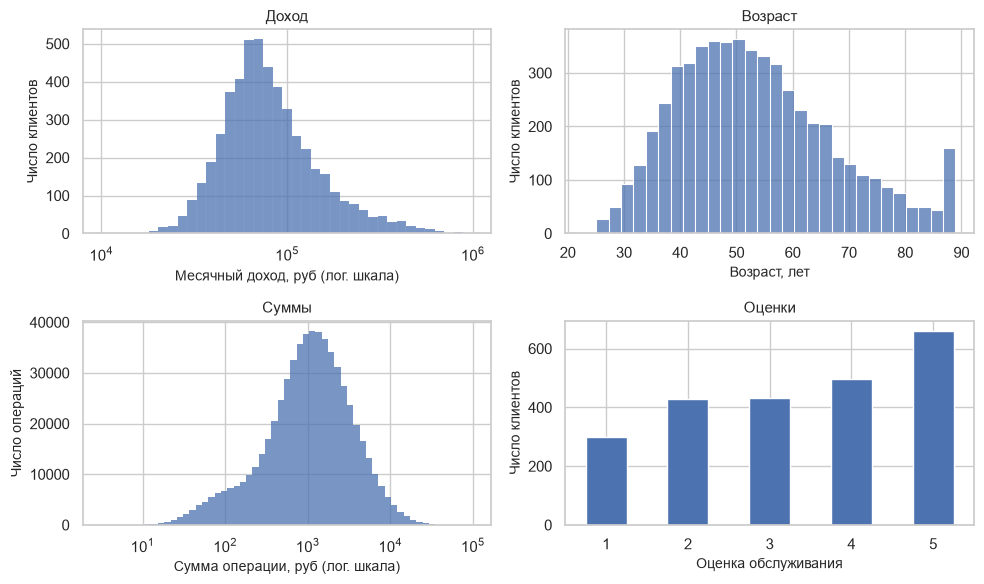

In [34]:
OK = transactions[in_per & is_ok & in_dir].copy()
OK["ym"] = OK.txn_datetime.dt.to_period("M")
OK["per"] = np.where(OK.txn_datetime < EVAL_START, "base", "eval")
print("OK: операций", len(OK), "| клиентов", OK.client_id.nunique())

def describe_num(s, name, unit):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75])
    sk = s.skew(); mad = (s - s.median()).abs().median()
    return dict(признак=name, ед=unit, n=len(s), среднее=round(s.mean(), 1), медиана=round(s.median(), 1), s=round(s.std(), 1),
                МКР=round(q3 - q1, 1), МАО=round(mad, 1), асимметрия=round(sk, 2),
                выбор=("медиана и МКР (скошено вправо)" if abs(sk) > 0.5 else "среднее и s (приблизительно симметрично)"))

age = (EVAL_END - clients.birth_date).dt.days / 365.25
clients["age"] = age
stats = pd.DataFrame([describe_num(clients.monthly_income, "monthly_income", "руб/мес"), describe_num(age, "возраст на 30.06.2025", "лет"),
                      describe_num(ok_rub.amount, "сумма успешной RUB-операции", "руб")])

display(stats)
sat = clients.satisfaction_score.dropna().astype(int)
print(f"satisfaction_score — порядковая шкала 1-5 (n ответивших = {len(sat)} из {len(clients)} клиентов)")
print("доли оценок среди ответивших (знаменатель", len(sat), "):", (sat.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
sns.histplot(clients.monthly_income.dropna(), bins=np.logspace(4, 6, 40), ax=ax[0, 0], color="#4C72B0"); ax[0, 0].set_xscale("log")
ax[0, 0].set_xlabel("Месячный доход, руб (лог. шкала)"); ax[0, 0].set_ylabel("Число клиентов"); ax[0, 0].set_title("Доход")
sns.histplot(age, bins=30, ax=ax[0, 1], color="#4C72B0"); ax[0, 1].set_xlabel("Возраст, лет"); ax[0, 1].set_ylabel("Число клиентов"); ax[0, 1].set_title("Возраст")
sns.histplot(ok_rub.amount, bins=np.logspace(0.5, 5, 60), ax=ax[1, 0], color="#4C72B0"); ax[1, 0].set_xscale("log")
ax[1, 0].set_xlabel("Сумма операции, руб (лог. шкала)"); ax[1, 0].set_ylabel("Число операций"); ax[1, 0].set_title("Суммы")
sat.value_counts().sort_index().plot.bar(ax=ax[1, 1], color="#4C72B0", rot=0); ax[1, 1].set_xlabel("Оценка обслуживания"); ax[1, 1].set_ylabel("Число клиентов")
ax[1, 1].set_title("Оценки"); plt.tight_layout(); plt.show()

### 5.2. Частотные характеристики категориальных признаков


**клиенты справочника, знаменатель = 5641 клиентов (30.06.2025)**


city
                    n  % от клиентов
city                                
Москва           1619           28.7
Санкт-Петербург   965           17.1
Новосибирск       924           16.4
Нижний Новгород   723           12.8
Екатеринбург      711           12.6
Казань            685           12.1
NaN                14            0.2

segment
                n  % от клиентов
segment                         
Массовый     2904           51.5
Зарплатный   1570           27.8
Премиальный   914           16.2
Private       241            4.3
NaN            12            0.2

loyalty_tier
                 n  % от клиентов
loyalty_tier                     
Базовый       2802           49.7
Серебро       1535           27.2
Золото        1030           18.3
Платина        274            4.9

card_type
                n  % от клиентов
card_type                       
Дебетовая    3928           69.6
Кредитная    1190           21.1
Премиальная   523            9.3

income_source
            

**сегмент x уровень лояльности, % внутри сегмента (знаменатель — клиенты сегмента):**

loyalty_tier  Базовый  Золото  Платина  Серебро
segment                                        
Private           2.1    42.7     46.1      9.1
Зарплатный       43.8    18.7      2.6     34.9
Массовый         69.5     7.5      0.7     22.3
Премиальный       9.3    45.3     11.2     34.2


**сегмент x приложение / согласие, % внутри сегмента:**

             has_mobile_app  marketing_opt_in
segment                                      
Private                63.1              91.3
Зарплатный             61.8              87.5
Массовый               62.2              88.6
Премиальный            63.2              87.9


**операции периода (после удаления дублей), знаменатель = 626,930 строк


status
                n  % от операций
status                          
успешно    606960           96.8
отклонено   12455            2.0
возврат      7515            1.2

channel
                  n  % от операций
channel                           
Карта        316239           50.4
СБП          108978           17.4
Токен        106497           17.0
Онлайн-банк   95216           15.2

currency
               n  % от операций
currency                       
RUB       624475           99.6
EUR         1247            0.2
USD         1208            0.2


**категория трат, успешные операции, знаменатель = 576,988**

                          n  % от успешных операций  накопл. %
category                                                      
Продукты             152155                    26.4       26.4
Кафе и рестораны      75402                    13.1       39.5
Транспорт             60449                    10.5       50.0
Одежда и обувь        58542                    10.1       60.1
АЗС                   53259                     9.2       69.3
Развлечения и досуг   49736                     8.6       77.9
Связь и интернет      45051                     7.8       85.7
Аптеки                42254                     7.3       93.0
Онлайн-сервисы        40140                     7.0      100.0


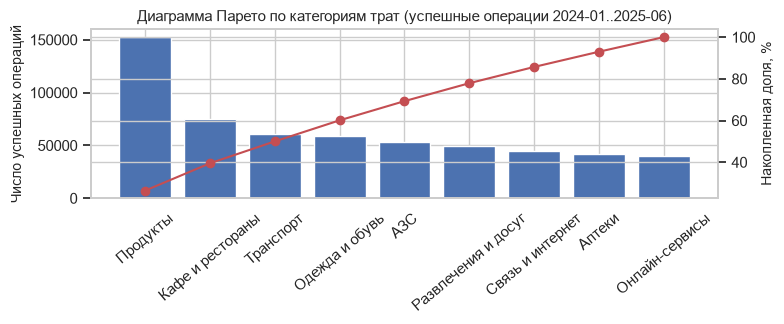

In [35]:
def freq(s, denom_name, denom):
    t = s.value_counts(dropna=False).rename("n").to_frame(); t["% от " + denom_name] = (t.n / denom * 100).round(1); return t
    
N_cl = len(clients)
display(Markdown(f"\n**клиенты справочника, знаменатель = {N_cl} клиентов (30.06.2025)**"))

for col in ["city", "segment", "loyalty_tier", "card_type", "income_source", "has_mobile_app", "marketing_opt_in"]:
    print(f"\n{col}"); print(freq(clients[col], "клиентов", N_cl).to_string())
    
display(Markdown("**сегмент x уровень лояльности, % внутри сегмента (знаменатель — клиенты сегмента):**"))
print((pd.crosstab(clients.segment, clients.loyalty_tier, normalize="index") * 100).round(1).to_string())

display(Markdown("**сегмент x приложение / согласие, % внутри сегмента:**"))
print(
    (clients
       .assign(
           has_mobile_app  = clients["has_mobile_app"].eq("Да"),
           marketing_opt_in = clients["marketing_opt_in"].eq("Да"),
       )
       .groupby("segment", observed=True)[["has_mobile_app", "marketing_opt_in"]]
       .mean() * 100
    ).round(1).to_string()
)

in_per_all = transactions[in_per]

display(Markdown(f"**операции периода (после удаления дублей), знаменатель = {len(in_per_all):,} строк"))
for col in ["status", "channel", "currency"]:
    print(f"\n{col}"); print(freq(in_per_all[col], "операций", len(in_per_all)).to_string())

display(Markdown(f"**категория трат, успешные операции, знаменатель = {len(OK):,}**"))
catf = freq(OK.category, "успешных операций", len(OK)); catf["накопл. %"] = catf.iloc[:, 1].cumsum().round(1); print(catf.to_string())
fig, ax = plt.subplots(figsize=(8, 3.4)); ax2 = ax.twinx()
ax.bar(catf.index.astype(str), catf.n, color="#4C72B0"); ax2.plot(catf.index.astype(str), catf["накопл. %"], color="#C44E52", marker="o")
ax.set_ylabel("Число успешных операций"); ax2.set_ylabel("Накопленная доля, %"); ax.tick_params(axis="x", rotation=40); ax.set_title("Диаграмма Парето по категориям трат (успешные операции 2024-01..2025-06)"); plt.tight_layout(); plt.show()

### 5.3. Динамика по месяцам

Оцениваемые клиенты (cohort): n = 4841; операции — успешные, 2024-01..2025-06, EUR/USD в счетчике, но не в суммах


,операций,активных клиентов,"сумма, млн руб","средний чек, руб","медианный чек, руб",операций на оцениваемого клиента
ym,,,,,,
2024-01,24317,4645,46.16,1905.0,1119.0,5.02
2024-02,30137,4710,58.59,1951.0,1128.0,6.23
2024-03,34817,4763,66.81,1926.0,1108.0,7.19
2024-04,34002,4758,64.93,1918.0,1116.0,7.02
2024-05,31436,4737,59.81,1909.0,1110.0,6.49
2024-06,33657,4746,64.56,1925.0,1122.0,6.95
2024-07,34631,4764,66.81,1937.0,1120.0,7.15
2024-08,35385,4765,67.80,1923.0,1124.0,7.31
2024-09,33686,4770,65.09,1941.0,1117.0,6.96


,"2024, среднее за месяц (12 мес.)","янв-июн 2025, среднее за месяц (6 мес.)","изменение, %"
операций,33639.25,26858.67,-20.2
активных клиентов,4747.83,4451.00,-6.3
"сумма, млн руб",64.72,48.39,-25.2
"средний чек, руб",1930.75,1808.17,-6.3
"медианный чек, руб",1120.33,1015.17,-9.4
операций на оцениваемого клиента,6.95,5.55,-20.1


Сезонность: Дек-2024 = 42,315 операций (+26% к среднему 2024) — предновогодний пик; сравнение «янв-июн к янв-июн»: 31,394 -> 26,859 операций/мес (-14.4%) против -20.2% при сравнении с 12-месячной базой


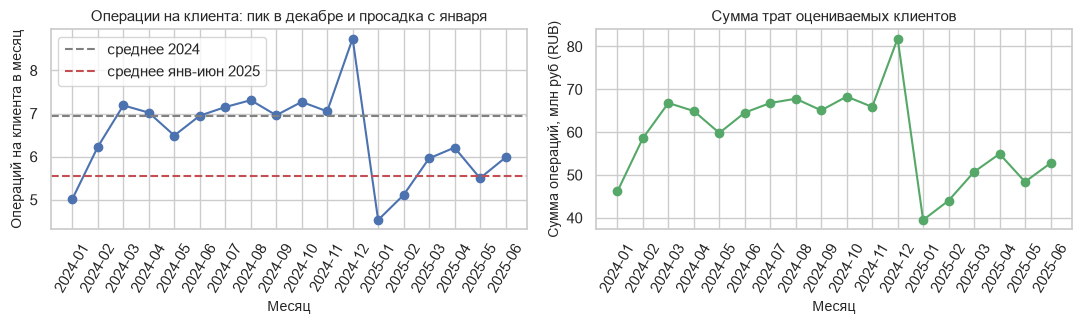


Операции клиентов, которых нет в справочнике действующих (ушли), по месяцам:
txn_datetime               2024-01  2024-02  2024-03  2024-04  2024-05  2024-06  2024-07  2024-08  2024-09  2024-10  2024-11  2024-12  2025-01  2025-02  2025-03
операций                      1747     2208     2487     2398     2275     2467     2548     2588     2379     2608     2217     2216      889      593      352
активных ушедших клиентов      349      349      349      354      348      352      352      355      352      356      299      247      179      119       54
Падение среднемесячных операций: оцениваемые клиенты -20.2%; все клиенты справочника (с новыми картами) -17.0%; ВМЕСТЕ с ушедшими (нет в справочнике) -21.5% — ушедшие и новые карты сдвигают общую картину, поэтому сравниваем фиксированную когорту


In [36]:
cohort_ids = set(clients.client_id[clients.in_cohort])
OKc = OK[OK.client_id.isin(cohort_ids)]
n_coh = len(cohort_ids)
rub = OKc[OKc.currency == "RUB"]

mon = pd.DataFrame({"операций": OKc.groupby("ym").size(), "активных клиентов": OKc.groupby("ym").client_id.nunique(),
                    "сумма, млн руб": (rub.groupby("ym").amount.sum() / 1e6).round(2),
                    "средний чек, руб": rub.groupby("ym").amount.mean().round(0), "медианный чек, руб": rub.groupby("ym").amount.median().round(0)})

mon["операций на оцениваемого клиента"] = (mon["операций"] / n_coh).round(2)

print(f"Оцениваемые клиенты (cohort): n = {n_coh}; операции — успешные, 2024-01..2025-06, EUR/USD в счетчике, но не в суммах")

display(mon)

bm = mon.loc[:"2024-12"].mean(); em = mon.loc["2025-01":].mean()
cmp_ = pd.DataFrame({"2024, среднее за месяц (12 мес.)": bm, "янв-июн 2025, среднее за месяц (6 мес.)": em}).round(2)
cmp_["изменение, %"] = ((em / bm - 1) * 100).round(1)
display(cmp_)

h1_24 = mon.loc["2024-01":"2024-06", "операций"].mean(); h1_25 = mon.loc["2025-01":"2025-06", "операций"].mean()
print(f"Сезонность: Дек-2024 = {mon.loc['2024-12','операций']:,} операций ({mon.loc['2024-12','операций']/bm['операций']*100-100:+.0f}% к среднему 2024) — предновогодний пик; "
      f"сравнение «янв-июн к янв-июн»: {h1_24:,.0f} -> {h1_25:,.0f} операций/мес ({(h1_25/h1_24-1)*100:+.1f}%) против {(em['операций']/bm['операций']-1)*100:+.1f}% при сравнении с 12-месячной базой")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
x = mon.index.astype(str); ax[0].plot(x, mon["операций на оцениваемого клиента"], marker="o", color="#4C72B0")
ax[0].axhline(bm["операций"] / n_coh, color="gray", ls="--", label="среднее 2024"); ax[0].axhline(em["операций"] / n_coh, color="#C44E52", ls="--", label="среднее янв-июн 2025")
ax[0].set_ylabel("Операций на клиента в месяц"); ax[0].set_xlabel("Месяц"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend(); ax[0].set_title("Операции на клиента: пик в декабре и просадка с января")
ax[1].plot(x, mon["сумма, млн руб"], marker="o", color="#55A868"); ax[1].set_ylabel("Сумма операций, млн руб (RUB)"); ax[1].set_xlabel("Месяц"); ax[1].tick_params(axis="x", rotation=60); ax[1].set_title("Сумма трат оцениваемых клиентов")
plt.tight_layout(); plt.show()

orph = transactions[in_per & is_ok & ~in_dir]
om = pd.DataFrame({"операций": orph.groupby(orph.txn_datetime.dt.to_period("M")).size(), "активных ушедших клиентов": orph.groupby(orph.txn_datetime.dt.to_period("M")).client_id.nunique()})
print("\nОперации клиентов, которых нет в справочнике действующих (ушли), по месяцам:"); print(om.T.to_string())
tot_dir = OK.groupby("per").size(); tot_coh = OKc.groupby("per").size()
tot_inc = transactions[in_per & is_ok].groupby(np.where(transactions.txn_datetime[in_per & is_ok] < EVAL_START, "base", "eval")).size()
f = lambda t: ((t["eval"] / 6) / (t["base"] / 12) - 1) * 100
print(f"Падение среднемесячных операций: оцениваемые клиенты {f(tot_coh):+.1f}%; все клиенты справочника (с новыми картами) {f(tot_dir):+.1f}%; "
      f"ВМЕСТЕ с ушедшими (нет в справочнике) {f(tot_inc):+.1f}% — ушедшие и новые карты сдвигают общую картину, поэтому сравниваем фиксированную когорту")

### 5.4. Разрезы и связи между признаками

In [37]:
coh = clients[clients.in_cohort].set_index("client_id").copy()
cnt = OKc.groupby(["client_id", "per"]).size().unstack("per", fill_value=0).reindex(coh.index, fill_value=0)
coh["ops_base"] = cnt["base"]; coh["ops_eval"] = cnt["eval"]
coh["b_m"] = coh.ops_base / BASE_MONTHS
coh["e_m"] = coh.ops_eval / EVAL_MONTHS

assert (coh.b_m > 0).all(), "у всех оцениваемых клиентов должна быть активность в базовом периоде"

coh["ratio"] = coh.e_m / coh.b_m
coh["change_pct"] = (coh.ratio - 1) * 100
q2 = OKc[OKc.txn_datetime >= "2025-04-01"].groupby("client_id").size().reindex(coh.index, fill_value=0) / 3
coh["ratio_q2"] = q2 / coh.b_m

for ch in ["Карта", "Токен", "СБП", "Онлайн-банк"]:
    c_ = OKc[OKc.channel == ch].groupby(["client_id", "per"]).size().unstack("per", fill_value=0).reindex(coh.index, fill_value=0)
    coh[f"ch_{ch}_base"] = c_["base"]; coh[f"ch_{ch}_eval"] = c_["eval"]

ent = OKc[OKc.category == "Развлечения и досуг"].groupby(["client_id", "per"]).size().unstack("per", fill_value=0).reindex(coh.index, fill_value=0)
coh["ent_base"] = ent["base"]; coh["ent_eval"] = ent["eval"]
coh["agegrp"] = pd.cut(coh.age, [0, 40, 60, 120], labels=["до 40", "41-60", "старше 60"])
coh["app"] = np.where(coh.has_mobile_app, "с приложением", "без приложения")

def cut(by, d=coh):
    g = d.groupby(by, observed=True, dropna=False).agg(n=("b_m", "size"), база_мес=("b_m", "mean"), оцен_мес=("e_m", "mean"))
    g["изменение, %"] = ((g.оцен_мес / g.база_мес - 1) * 100).round(1)
    return g.round(2)
    
print(f"оцениваемых клиентов: {len(coh)}; средняя активность: {coh.b_m.mean():.2f} -> {coh.e_m.mean():.2f} операций/клиента/мес ({(coh.e_m.mean()/coh.b_m.mean()-1)*100:+.1f}%)")
for by in ["segment", "app", "loyalty_tier", "income_source", "card_type", "agegrp", "city", "marketing_opt_in"]:
    display(Markdown(f"**{by} (n = клиенты cohort; изменение = среднемесячное оцен. / база - 1)**")); print(cut(by).to_string())

оцениваемых клиентов: 4841; средняя активность: 6.95 -> 5.55 операций/клиента/мес (-20.2%)


**segment (n = клиенты cohort; изменение = среднемесячное оцен. / база - 1)**

                n  база_мес  оцен_мес  изменение, %
segment                                            
Private       195      8.71      7.43         -14.8
Зарплатный   1312      7.86      7.11          -9.6
Массовый     2582      5.92      3.98         -32.8
Премиальный   752      8.42      7.72          -8.4


**app (n = клиенты cohort; изменение = среднемесячное оцен. / база - 1)**

                  n  база_мес  оцен_мес  изменение, %
app                                                  
с приложением  4841      6.95      5.55         -20.2


**loyalty_tier (n = клиенты cohort; изменение = среднемесячное оцен. / база - 1)**

... (7 outputs left out)

**city (n = клиенты cohort; изменение = среднемесячное оцен. / база - 1)**

                    n  база_мес  оцен_мес  изменение, %
city                                                   
Екатеринбург      615      7.16      5.58         -22.0
Казань            567      7.08      5.63         -20.6
Москва           1387      7.00      5.72         -18.3
Нижний Новгород   615      7.39      6.16         -16.7
Новосибирск       826      6.02      4.24         -29.6
Санкт-Петербург   831      7.22      6.04         -16.4


**marketing_opt_in (n = клиенты cohort; изменение = среднемесячное оцен. / база - 1)**

                     n  база_мес  оцен_мес  изменение, %
marketing_opt_in                                        
Да                4268      6.95      5.54         -20.3
Нет                573      6.95      5.63         -19.0


**КАТЕГОРИИ**

per                  база/мес  оцен/мес  изменение, %
category                                             
АЗС                    3064.0    2553.0         -16.7
Аптеки                 2476.0    1947.0         -21.4
Кафе и рестораны       4328.0    3629.0         -16.2
Одежда и обувь         3373.0    2804.0         -16.9
Онлайн-сервисы         2316.0    1915.0         -17.3
Продукты               8850.0    7141.0         -19.3
Развлечения и досуг    3083.0    1956.0         -36.6
Связь и интернет       2631.0    2087.0         -20.7
Транспорт              3517.0    2826.0         -19.6

КАНАЛЫ
per          база/мес  оцен/мес  изменение, %
channel                                      
Карта         17492.0   12416.0         -29.0
Онлайн-банк    5054.0    4080.0         -19.3
СБП            6055.0    4179.0         -31.0
Токен          5038.0    6184.0          22.7


**КАНАЛЫ по наличию приложения:**

с приложением (n = 4841 ) {'Карта': -29.0, 'Онлайн-банк': -19.3, 'СБП': -31.0, 'Токен': 22.7}


**СЕГМЕНТ x приложение, изменение %, n:**

                        n           изм
app         с приложением с приложением
segment                                
Private               195         -14.8
Зарплатный           1312          -9.6
Массовый             2582         -32.8
Премиальный           752          -8.4


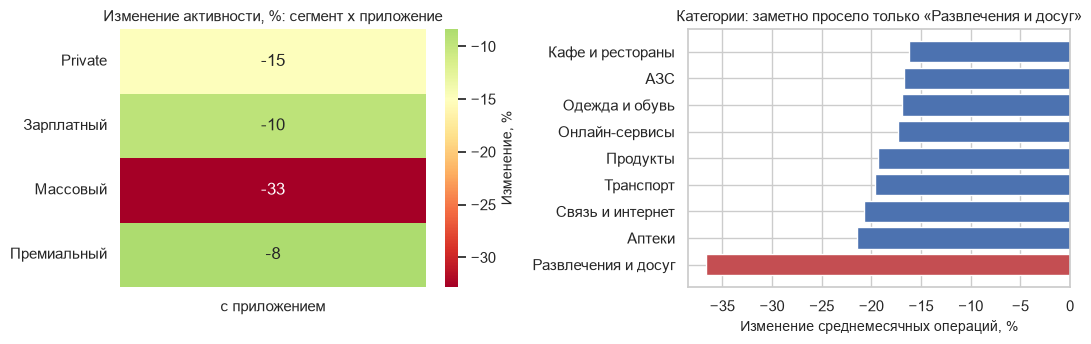

In [38]:
def chg_by(col):
    g = OKc.groupby([col, "per"], observed=True).size().unstack("per")
    g["база/мес"] = (g["base"] / BASE_MONTHS).round(0); g["оцен/мес"] = (g["eval"] / EVAL_MONTHS).round(0)
    g["изменение, %"] = ((g["оцен/мес"] / g["база/мес"] - 1) * 100).round(1); return g[["база/мес", "оцен/мес", "изменение, %"]]
    
display(Markdown("**КАТЕГОРИИ**")); print(chg_by("category").to_string()); print("\nКАНАЛЫ"); print(chg_by("channel").to_string())
display(Markdown("**КАНАЛЫ по наличию приложения:**"))
for app, d in coh.groupby("app"):
    ids = set(d.index); x = OKc[OKc.client_id.isin(ids)].groupby(["channel", "per"], observed=True).size().unstack("per")
    print(app, "(n =", len(d), ")", ((x["eval"] / 6) / (x["base"] / 12) * 100 - 100).round(1).to_dict())
    
display(Markdown("**СЕГМЕНТ x приложение, изменение %, n:**")); 
hm = coh.groupby(["segment", "app"], observed=True).agg(n=("b_m", "size"), b=("b_m", "mean"), e=("e_m", "mean")); hm["изм"] = ((hm.e / hm.b - 1) * 100).round(1); print(hm[["n", "изм"]].unstack("app").to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
pv = hm["изм"].unstack("app"); sns.heatmap(pv, annot=True, fmt=".0f", cmap="RdYlGn", center=-15, ax=ax[0], cbar_kws={"label": "Изменение, %"}); ax[0].set_title("Изменение активности, %: сегмент x приложение"); ax[0].set_xlabel(""); ax[0].set_ylabel("")
cg = chg_by("category")["изменение, %"].sort_values(); ax[1].barh(cg.index.astype(str), cg.values, color=["#C44E52" if v < -25 else "#4C72B0" for v in cg.values]); ax[1].set_xlabel("Изменение среднемесячных операций, %"); ax[1].set_title("Категории: заметно просело только «Развлечения и досуг»")
plt.tight_layout(); plt.show()

In [39]:
coh["has_mobile_app"]   = coh.has_mobile_app.eq("Да")
coh["marketing_opt_in"] = coh.marketing_opt_in.eq("Да")

def chg(d): return (d.e_m.mean() / d.b_m.mean() - 1) * 100
H = {}
a, b = coh[~coh.has_mobile_app], coh[coh.has_mobile_app]
H["H1 без приложения снизили активность сильнее"] = f"без приложения {chg(a):+.1f}% (n={len(a)}), с приложением {chg(b):+.1f}% (n={len(b)}); внутри массового сегмента {chg(a[a.segment=='Массовый']):+.1f}% vs {chg(b[b.segment=='Массовый']):+.1f}%"
s_o, s_d = coh[coh.income_source == "Зарплата в нашем банке"], coh[coh.income_source != "Зарплата в нашем банке"]
H["H2 «Зарплата в нашем банке» — стабильнее"] = f"{chg(s_o):+.1f}% (n={len(s_o)}) vs {chg(s_d):+.1f}% (n={len(s_d)}); внутри Массового: {chg(s_o[s_o.segment=='Массовый']):+.1f}% vs {chg(s_d[s_d.segment=='Массовый']):+.1f}% -> различие объясняется сегментом"
ns = coh[coh.city == "Новосибирск"]; ot = coh[coh.city != "Новосибирск"]
H["H3 Новосибирск просел сильнее"] = f"{chg(ns):+.1f}% (n={len(ns)}) vs {chg(ot):+.1f}% (n={len(ot)}); но в Новосибирске {ns.segment.eq('Массовый').mean()*100:.0f}% Массовых (в остальных {ot.segment.eq('Массовый').mean()*100:.0f}%); внутри Массового {chg(ns[ns.segment=='Массовый']):+.1f}% vs {chg(ot[ot.segment=='Массовый']):+.1f}%"
mo, mn = coh[coh.marketing_opt_in], coh[~coh.marketing_opt_in]
H["H4 согласие на маркетинг связано с падением"] = f"с согласием {chg(mo):+.1f}% (n={len(mo)}), без {chg(mn):+.1f}% (n={len(mn)})"
sl, sh = coh[coh.satisfaction_score <= 2], coh[coh.satisfaction_score >= 4]
H["H5 недовольные снизили активность сильнее"] = f"оценка 1-2: {chg(sl):+.1f}% (n={len(sl)}); оценка 4-5: {chg(sh):+.1f}% (n={len(sh)}); внутри Массового 1-2: {chg(sl[sl.segment=='Массовый']):+.1f}% (n={int((sl.segment=='Массовый').sum())}), 4-5: {chg(sh[sh.segment=='Массовый']):+.1f}% (n={int((sh.segment=='Массовый').sum())}); ответили только {coh.satisfaction_score.notna().mean()*100:.0f}%"
lg = coh[coh.has_mobile_app].copy(); lg["recent"] = lg.app_last_login >= "2025-01-01"
H["H6 давность входа в приложение связана с падением"] = f"вход в 2025: {chg(lg[lg.recent]):+.1f}% (n={int(lg.recent.sum())}); последний вход раньше 2025: {chg(lg[~lg.recent]):+.1f}% (n={int((~lg.recent).sum())}); внутри Массового {chg(lg[lg.recent&(lg.segment=='Массовый')]):+.1f}% vs {chg(lg[~lg.recent&(lg.segment=='Массовый')]):+.1f}%"
o70, y70 = coh[coh.age > 70], coh[coh.age <= 70]
H["H7 клиенты старше 70 просели сильнее"] = f"{chg(o70):+.1f}% (n={len(o70)}) vs {chg(y70):+.1f}% (n={len(y70)}); внутри Массового: {chg(o70[o70.segment=='Массовый']):+.1f}% vs {chg(y70[y70.segment=='Массовый']):+.1f}%"
cc = chg_by("channel"); H["H8 падение «карты» — это падение активности"] = f"операции по каналу «Карта» {cc.loc['Карта','изменение, %']:+.1f}%, но «Токен» {cc.loc['Токен','изменение, %']:+.1f}%; итого по всем каналам {(coh.e_m.mean()/coh.b_m.mean()-1)*100:+.1f}%"
for k, v in H.items(): print(f"{k}:\n    {v}")

H1 без приложения снизили активность сильнее:
    без приложения -26.5% (n=1868), с приложением -16.6% (n=2973); внутри массового сегмента -42.5% vs -27.1%
H2 «Зарплата в нашем банке» — стабильнее:
    -15.2% (n=2122) vs -24.5% (n=2719); внутри Массового: -33.0% vs -32.7% -> различие объясняется сегментом
H3 Новосибирск просел сильнее:
    -29.6% (n=826) vs -18.5% (n=4015); но в Новосибирске 89% Массовых (в остальных 46%); внутри Массового -33.6% vs -32.4%
H4 согласие на маркетинг связано с падением:
    с согласием -20.3% (n=4268), без -19.0% (n=573)
H5 недовольные снизили активность сильнее:
    оценка 1-2: -20.4% (n=627); оценка 4-5: -16.9% (n=987); внутри Массового 1-2: -31.0% (n=318), 4-5: -32.0% (n=440); ответили только 41%
H6 давность входа в приложение связана с падением:
    вход в 2025: -16.5% (n=964); последний вход раньше 2025: -16.6% (n=2009); внутри Массового -27.1% vs -27.0%
H7 клиенты старше 70 просели сильнее:
    -28.0% (n=673) vs -19.2% (n=4168); внутри Массового: -4

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

**Метрика:** число успешных операций клиента в среднем за месяц, ops/мес = успешные операции за окно / число месяцев окна - для базового периода 2024 (12 месяцев) и для оцениваемого января–июня 2025 (6 месяцев). Снижение - падение этого значения более чем вдвое (ratio = оцен./база ≤ 0,5).

Выбрано именно число, а не сумма, так как:
1. Сумма определяется несколькими крупными покупками и для EUR/USD невычислима без курса; число операций устойчиво к хвосту.
2. Активность использования карты - это привычка пользоваться, а не размер чека.
3. Отклоненные и возвратные операции не считаются: клиент ими не «пользуется».

Окна сравниваем средним за месяц, так как 12 и 6 месяцев нельзя сравнивать суммами. Дополнительная проблема - сезонность: в декабре 2024 пик, а в январе провал; поэтому падение к 12-месячной базе завышено

Сезонность: все оцениваемые: -20.2% к 12-мес. базе; но «янв-июн 2025 к янв-июн 2024»: -14.4%
Типичный «сохранившийся» клиент (ratio>0.5) сохраняет медианно 90% базовой активности — это и есть сезонный фон


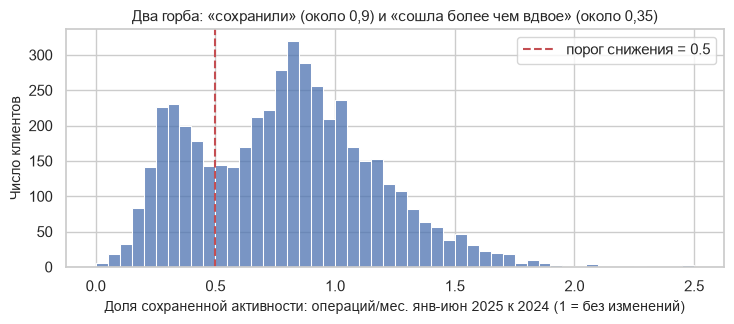

Шум: при стабильном поведении у всех (Пуассон, seed=42) ratio <= 0.5 получили бы по случайности 1.2% клиентов; фактически 26.6%


,порог ratio,клиентов со снижением,% от оцениваемых (n=4841),"из них Массовый, %"
0,0.4,950,19.6,82.6
1,0.5,1287,26.6,80.1
2,0.6,1543,31.9,76.9
3,0.7,1924,39.7,71.7


Согласованность во времени у снизившихся (ratio<=0.5): медиана ratio за янв-мар vs апр-июн: 0.37 vs 0.26


In [40]:
st = coh[coh.ratio > DROP_THRESHOLD]
print(f"Сезонность: все оцениваемые: {(coh.e_m.mean()/coh.b_m.mean()-1)*100:+.1f}% к 12-мес. базе; но «янв-июн 2025 к янв-июн 2024»: ", end="")
h1 = OKc[(OKc.txn_datetime >= "2024-01-01") & (OKc.txn_datetime < "2024-07-01")].groupby("client_id").size().reindex(coh.index, fill_value=0) / 6
print(f"{(coh.e_m.mean()/h1.mean()-1)*100:+.1f}%")
season = coh.ratio[coh.ratio > DROP_THRESHOLD].median()
print(f"Типичный «сохранившийся» клиент (ratio>{DROP_THRESHOLD}) сохраняет медианно {season*100:.0f}% базовой активности — это и есть сезонный фон")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
sns.histplot(coh.ratio.clip(upper=2.5), bins=50, color="#4C72B0", ax=ax); ax.axvline(DROP_THRESHOLD, color="#C44E52", ls="--", label=f"порог снижения = {DROP_THRESHOLD}")
ax.set_xlabel("Доля сохраненной активности: операций/мес. янв-июн 2025 к 2024 (1 = без изменений)"); ax.set_ylabel("Число клиентов"); ax.legend(); ax.set_title("Два горба: «сохранили» (около 0,9) и «сошла более чем вдвое» (около 0,35)"); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
sim_e = rng.poisson(lam=coh.b_m.values * season * EVAL_MONTHS)
fp = ((sim_e / EVAL_MONTHS) / coh.b_m.values <= DROP_THRESHOLD).mean()
print(f"Шум: при стабильном поведении у всех (Пуассон, seed={SEED}) ratio <= {DROP_THRESHOLD} получили бы по случайности {fp*100:.1f}% клиентов; фактически {(coh.ratio<=DROP_THRESHOLD).mean()*100:.1f}%")
sens = pd.DataFrame({"порог ratio": [0.4, 0.5, 0.6, 0.7]})
sens["клиентов со снижением"] = [int((coh.ratio <= t).sum()) for t in sens["порог ratio"]]; sens[f"% от оцениваемых (n={len(coh)})"] = (sens["клиентов со снижением"] / len(coh) * 100).round(1)
sens["из них Массовый, %"] = [round(coh[coh.ratio <= t].segment.eq("Массовый").mean() * 100, 1) for t in sens["порог ratio"]]
display(sens)
print("Согласованность во времени у снизившихся (ratio<=0.5): медиана ratio за янв-мар vs апр-июн:",
      round(((OKc[(OKc.txn_datetime >= '2025-01-01') & (OKc.txn_datetime < '2025-04-01')].groupby('client_id').size().reindex(coh.index, fill_value=0) / 3) / coh.b_m)[coh.ratio <= 0.5].median(), 2), "vs", round(coh.ratio_q2[coh.ratio <= 0.5].median(), 2))

**Какое снижение метрика не увидит**:

1. **Уход клиента из банка и закрытие карты.** В справочнике только действующие клиенты; ушедшие (client_id есть в операциях, но нет в справочнике) в оценку не входят. Статуса закрытия карты в данных нет.
2. **Перенос трат на другую карту, наличные или чужие каналы.** Метрика видит только операции по картам банка; куда клиент ушёл, по ней не понять.
3. **Падение суммы при сохранении числа операций** (покупки стали мельче): число операций почти не меняется.
4. **Перетекание между каналами.** Переход "Карта/СБП - Токен" метрика не считает падением (суммарно операций столько же) - это верно для кампании, но видно только по разрезу каналов.
5. **Клиентов с неполной историей**.
6. **Сезонность:** при сравнении с 12-месячной базой часть "снижения" - декабрьский пик и январский провал (оценка выше); индивидуальный шум при ~7 операциях в месяц велик, поэтому решения принимаются на уровне групп, а порог 0,5 лежит в провале между горбами.

## 7. Поиск и описание групп

Правило отбора для каждой группы, ее размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

**Что нашли в разведке:** падение активности — смесь трех разных явлений:

1. **Широкий спад:** у части клиентов активность упала примерно на две трети во всех категориях и во всех каналах сразу. Таких клиентов много среди Массового сегмента, особенно без приложения.
2. **Избирательный спад:** у остальных клиентов все стабильно, кроме категории «Развлечения и досуг» (у части — почти исчезла).
3. **Перенос способа оплаты:** у клиентов с приложением операции «Карта»/«СБП» → «Токен». Общая активность при этом не падает — это не повод для кампании.

In [41]:
broad = coh.ratio <= DROP_THRESHOLD
ENT_MIN_BASE, ENT_MAX_EVAL = 12, 1
ent_gone = (coh.ent_base >= ENT_MIN_BASE) & (coh.ent_eval <= ENT_MAX_EVAL)
mass = coh.segment == "Массовый"
GROUPS = {
 "G1": "Массовый сегмент, без приложения: активность упала более чем вдвое по всем категориям и каналам",
 "G2": "Массовый сегмент, с приложением: активность упала более чем вдвое по всем категориям и каналам",
 "G3": "Зарплатный, Премиальный, Private: активность упала более чем вдвое по всем категориям и каналам",
 "G4": "Любой сегмент, общая активность сохранилась (падение не более чем вдвое), но перестали пользоваться категорией «Развлечения и досуг»",
}
masks = {"G1": broad & mass & ~coh.has_mobile_app, "G2": broad & mass & coh.has_mobile_app, "G3": broad & ~mass, "G4": ~broad & ent_gone}

cand = pd.Series(np.select(list(masks.values()), list(masks.keys()), default=""), index=coh.index)
overlap = sum(m.astype(int) for m in masks.values())
print("клиентов, подходящих под более чем одну группу (должно быть 0):", int((overlap > 1).sum()))
coh["group_all"] = cand                                                    # до фильтра согласия
coh["group"] = np.where(coh.marketing_opt_in, cand, "")                    # итоговая принадлежность: только с согласием на маркетинг
sizes = pd.DataFrame({"клиентов, подходят правилу": cand.replace("", np.nan).value_counts().sort_index(),
                      "из них с согласием (в кампанию)": coh.group.replace("", np.nan).value_counts().sort_index()})
display(sizes)
print("итого в кампанию:", int((coh.group != "").sum()), "| лимит 2000; минимум по группе:", int(sizes.iloc[:, 1].min()), "(лимит 150) | групп:", len(sizes))

rng = np.random.default_rng(SEED); pool = coh[(~broad) & (coh.ent_base >= ENT_MIN_BASE)]
sim = rng.poisson(lam=pool.ent_base.values / BASE_MONTHS * EVAL_MONTHS * season)
print(f"G4, ложные срабатывания: из {len(pool)} клиентов с >={ENT_MIN_BASE} развлекательных операций в 2024 и сохранившейся активностью по случайности "
      f"({ENT_MAX_EVAL} или меньше операций при стабильном поведении) попали бы ~{(sim <= ENT_MAX_EVAL).sum()} (Пуассон, seed={SEED}); фактически {int(ent_gone[~broad].sum())} -> по порядку величины это реальное явление, оценка чистоты группы ниже")

клиентов, подходящих под более чем одну группу (должно быть 0): 0


,"клиентов, подходят правилу",из них с согласием (в кампанию)
G1,547,488
G2,484,439
G3,256,223
G4,251,220


итого в кампанию: 1370 | лимит 2000; минимум по группе: 220 (лимит 150) | групп: 4
G4, ложные срабатывания: из 802 клиентов с >=12 развлекательных операций в 2024 и сохранившейся активностью по случайности (1 или меньше операций при стабильном поведении) попали бы ~12 (Пуассон, seed=42); фактически 251 -> по порядку величины это реальное явление, оценка чистоты группы ниже


In [42]:
def grp_row(g, d):
    ids = set(d.index); x = OKc[OKc.client_id.isin(ids)]
    cat = x.groupby(["category", "per"], observed=True).size().unstack("per"); cat_chg = ((cat["eval"] / 6) / (cat["base"] / 12) - 1) * 100
    ch = x.groupby(["channel", "per"], observed=True).size().unstack("per"); ch_chg = ((ch["eval"] / 6) / (ch["base"] / 12) - 1) * 100
    return dict(группа=g, n=len(d), база_мес=round(d.b_m.mean(), 2), оцен_мес=round(d.e_m.mean(), 2), изменение_pct=round((d.e_m.mean() / d.b_m.mean() - 1) * 100, 1),
                ratio_янв_мар=round(d.ratio.median(), 2), ratio_апр_июн=round(d.ratio_q2.median(), 2),
                категории_мин_макс=f"{cat_chg.min():.0f}..{cat_chg.max():.0f}%", развлечения_pct=round(cat_chg["Развлечения и досуг"], 1),
                каналы_мин_макс=f"{ch_chg.min():.0f}..{ch_chg.max():.0f}%", токен_pct=round(ch_chg["Токен"], 1),
                доля_с_приложением_pct=round(d.has_mobile_app.mean() * 100, 0), возраст_медиана=round(d.age.median(), 0),
                базовый_доход_медиана=round(d.monthly_income.median(), -2), топ_город=d.city.value_counts().index[0])
camp = coh[coh.group != ""]
gt = pd.DataFrame([grp_row(g, camp[camp.group == g]) for g in sorted(camp.group.unique())]).set_index("группа")
display(gt.T)
stable_ref = coh[(~broad) & (~ent_gone)]
print(f"справка — остальные оцениваемые без широкого спада и без ухода из развлечений (n={len(stable_ref)}):", grp_row("ref", stable_ref))
print("\nсостав групп по сегментам и приложению (n):"); print(pd.crosstab(camp.group, [camp.segment.astype(str), camp.app]).to_string())
print("\nчувствительность к порогу широкого спада (размер групп с согласием): ")
rows = []
for thr in [0.4, 0.5, 0.6]:
    b_ = coh.ratio <= thr; o = coh.marketing_opt_in
    rows.append((thr, int((b_ & mass & ~coh.has_mobile_app & o).sum()), int((b_ & mass & coh.has_mobile_app & o).sum()), int((b_ & ~mass & o).sum()), int((~b_ & ent_gone & o).sum())))
display(pd.DataFrame(rows, columns=["порог ratio", "G1", "G2", "G3", "G4"]))

группа,G1,G2,G3,G4
n,488,439,223,220
база_мес,5.59,6.05,7.42,7.77
оцен_мес,1.78,2.01,2.57,5.64
изменение_pct,-68.1,-66.8,-65.4,-27.5
ratio_янв_мар,0.32,0.33,0.35,0.7
ratio_апр_июн,0.22,0.28,0.3,0.78
категории_мин_макс,-72..-67%,-68..-65%,-68..-61%,-96..5%
развлечения_pct,-70.4,-67.9,-68.5,-95.5
каналы_мин_макс,-73..-67%,-72..-64%,-69..-64%,-37..-19%
токен_pct,-66.8,-66.2,-63.6,-19.0


справка — остальные оцениваемые без широкого спада и без ухода из развлечений (n=3303): {'группа': 'ref', 'n': 3303, 'база_мес': np.float64(7.21), 'оцен_мес': np.float64(6.92), 'изменение_pct': np.float64(-4.0), 'ratio_янв_мар': np.float64(0.92), 'ratio_апр_июн': np.float64(1.0), 'категории_мин_макс': '-14..-3%', 'развлечения_pct': np.float64(-14.3), 'каналы_мин_макс': '-17..57%', 'токен_pct': np.float64(56.6), 'доля_с_приложением_pct': np.float64(67.0), 'возраст_медиана': np.float64(51.0), 'базовый_доход_медиана': np.float64(76800.0), 'топ_город': 'Москва'}

состав групп по сегментам и приложению (n):
segment       Private    Зарплатный      Массовый   Премиальный
app     с приложением с приложением с приложением с приложением
group                                                          
G1                  0             0           488             0
G2                  0             0           439             0
G3                 18           145             0            60
G4    

,порог ratio,G1,G2,G3,G4
0,0.4,384,319,144,236
1,0.5,488,439,223,220
2,0.6,545,513,314,189


### 7.1. Кого в кампанию не берем и почему

In [43]:
n_orph = transactions.client_id[in_per & is_ok & ~in_dir].nunique()
new24 = clients[(clients.card_open_date >= BASE_START) & (clients.card_open_date < EVAL_START) & ~clients.id_conflict]; new25 = clients[(clients.card_open_date >= EVAL_START) & ~clients.id_conflict]
would = (coh.group_all != "")
excl = pd.DataFrame([
 ("Ушли из банка до 30.06.2025 (есть в операциях, нет в справочнике)", n_orph, "нет атрибутов и согласия; вернуть их кампанией «по карте» нельзя — это отдельная задача удержания/возврата"),
 ("Конфликт client_id (две записи с разными сегментом/городом)", int(clients.id_conflict.sum()), "правила групп опираются на сегмент; запись неопределённа — сначала сверить в источнике"),
 ("Карта открыта в 2024 году (неполная база)", len(new24), "12 месяцев базы нет — падение оценить нельзя; растущая активность новой карты не падение"),
 ("Карта открыта в 2025 году (базы нет вовсе, в т.ч. 7 без операций)", len(new25), "нет базового периода — снижение не определено"),
 ("Подходят под правило группы, но нет согласия на маркетинг", int((would & ~coh.marketing_opt_in).sum()), "коммуникация без согласия невозможна (условие заказчика)"),
 ("Оцениваемые без снижения и без ухода из развлечений", int((coh.group_all == "").sum()), "активность в норме (сезонный фон); кампания им не нужна — риск раздражить"),
], columns=["категория", "клиентов", "почему не берем"])
display(excl)
print("Клиенты с аномальным доходом (-999 -> NaN, <1000 -> x1000):", int(clients.monthly_income.isna().sum()), "пропусков дохода,", int(clients.income_rescaled.sum()), "исправленных единиц — НЕ исключаются: доход не входит в правила групп")
print("Клиенты с 0 успешных операций в оцениваемом периоде среди оцениваемых:", int((coh.ops_eval == 0).sum()), "— включены в G1-G3 по правилу, если есть согласие")

,категория,клиентов,почему не берем
0,"Ушли из банка до 30.06.2025 (есть в операциях,...",359,нет атрибутов и согласия; вернуть их кампанией...
1,Конфликт client_id (две записи с разными сегме...,15,правила групп опираются на сегмент; запись нео...
2,Карта открыта в 2024 году (неполная база),456,12 месяцев базы нет — падение оценить нельзя; ...
3,"Карта открыта в 2025 году (базы нет вовсе, в т...",329,нет базового периода — снижение не определено
4,"Подходят под правило группы, но нет согласия н...",168,коммуникация без согласия невозможна (условие ...
5,Оцениваемые без снижения и без ухода из развле...,3303,активность в норме (сезонный фон); кампания им...


Клиенты с аномальным доходом (-999 -> NaN, <1000 -> x1000): 574 пропусков дохода, 162 исправленных единиц — НЕ исключаются: доход не входит в правила групп
Клиенты с 0 успешных операций в оцениваемом периоде среди оцениваемых: 4 — включены в G1-G3 по правилу, если есть согласие


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [44]:
verdict = {"H1": "подтвердилась, но в основном внутри Массового сегмента", "H2": "не подтвердилась: различие исчезает внутри сегмента",
           "H3": "не подтвердилась: эффект состава (доля Массового сегмента)", "H4": "не подтвердилась: разница ~1 п.п.",
           "H5": "не подтвердилась: внутри Массового нет различий", "H6": "не подтвердилась", "H7": "частично: внутри Массового 70+ ниже на ~9 п.п.", "H8": "не подтвердилась: падение «Карты» компенсирует рост «Токен»"}
hyp = pd.DataFrame([(k.split()[0], k[3:], verdict[k.split()[0]], v) for k, v in H.items()], columns=["№", "гипотеза", "итог", "числа (изменение среднемесячных операций, n)"])
pd.set_option("display.max_colwidth", 200); display(hyp)

,№,гипотеза,итог,"числа (изменение среднемесячных операций, n)"
0,H1,без приложения снизили активность сильнее,"подтвердилась, но в основном внутри Массового сегмента","без приложения -26.5% (n=1868), с приложением -16.6% (n=2973); внутри массового сегмента -42.5% vs -27.1%"
1,H2,«Зарплата в нашем банке» — стабильнее,не подтвердилась: различие исчезает внутри сегмента,-15.2% (n=2122) vs -24.5% (n=2719); внутри Массового: -33.0% vs -32.7% -> различие объясняется сегментом
2,H3,Новосибирск просел сильнее,не подтвердилась: эффект состава (доля Массового сегмента),-29.6% (n=826) vs -18.5% (n=4015); но в Новосибирске 89% Массовых (в остальных 46%); внутри Массового -33.6% vs -32.4%
3,H4,согласие на маркетинг связано с падением,не подтвердилась: разница ~1 п.п.,"с согласием -20.3% (n=4268), без -19.0% (n=573)"
4,H5,недовольные снизили активность сильнее,не подтвердилась: внутри Массового нет различий,"оценка 1-2: -20.4% (n=627); оценка 4-5: -16.9% (n=987); внутри Массового 1-2: -31.0% (n=318), 4-5: -32.0% (n=440); ответили только 41%"
5,H6,давность входа в приложение связана с падением,не подтвердилась,вход в 2025: -16.5% (n=964); последний вход раньше 2025: -16.6% (n=2009); внутри Массового -27.1% vs -27.0%
6,H7,клиенты старше 70 просели сильнее,частично: внутри Массового 70+ ниже на ~9 п.п.,-28.0% (n=673) vs -19.2% (n=4168); внутри Массового: -41.2% vs -31.7%
7,H8,падение «карты» — это падение активности,не подтвердилась: падение «Карты» компенсирует рост «Токен»,"операции по каналу «Карта» -29.0%, но «Токен» +22.7%; итого по всем каналам -20.2%"


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [45]:
metr_cols = ["ops_base", "ops_eval", "b_m", "e_m", "ratio", "change_pct", "ratio_q2", "ent_base", "ent_eval"] + [c for c in coh.columns if c.startswith("ch_")]
clean = clients.merge(coh[metr_cols + ["group_all", "group"]].reset_index(), on="client_id", how="left")
clean["group"] = clean.group.fillna(""); clean["group_all"] = clean.group_all.fillna("")
clean["decline"] = np.where(clean.in_cohort, clean.ratio <= DROP_THRESHOLD, np.nan)
for c in ["city", "segment", "loyalty_tier", "card_type", "income_source", "gender"]: clean[c] = clean[c].astype(str)
txn_clean = transactions[in_per & is_ok][["txn_id", "client_id", "txn_datetime", "amount", "currency", "category", "channel"]].copy()
txn_clean["category"] = txn_clean.category.astype(str); txn_clean["channel"] = txn_clean.channel.astype(str); txn_clean["currency"] = txn_clean.currency.astype(str)
txn_clean["in_directory"] = txn_clean.client_id.isin(clients.client_id)
print("clean_data:", clean.shape, "| txn_clean:", txn_clean.shape)

CLEAN_FMT = "parquet"
try:
    clean.to_parquet("clean_data.parquet", index=False); txn_clean.to_parquet("txn_clean.parquet", index=False)
except Exception as ex:
    CLEAN_FMT = "csv"
    clean.to_csv("clean_data.csv", index=False, encoding="utf-8"); txn_clean.to_csv("txn_clean.csv.gz", index=False, encoding="utf-8")
    print("parquet недоступен (", type(ex).__name__, ") -> сохранен csv")
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign = clean.loc[clean["group"] != "", ["client_id", "group"]].sort_values(["group", "client_id"]).reset_index(drop=True)
LABELS = {"G1": "G1: Массовый, без приложения - спад по всем категориям", "G2": "G2: Массовый, с приложением - спад по всем категориям",
          "G3": "G3: Зарплатный/Премиальный/Private - спад по всем категориям", "G4": "G4: общая активность сохранена, ушли из «Развлечений и досуга»"}
campaign["group"] = campaign.group.map(LABELS)
campaign.to_csv("campaign_list.csv", index=False, encoding="utf-8")

clean_data: (5641, 40) | txn_clean: (606960, 8)
